<a href="https://colab.research.google.com/github/molevanikaleksey/statistics_lab_sprint1/blob/main/LR_1_stat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab01.sprint 1**.

Участники:

Инфохимики:
502512 Молеваник Алексей, 502766 Фатхуллина София, 504704 Лемешкина Полина

Дизайнеры:
501809 Макарова Юлия, 504599 Степанова Дарья

Для работы был выбран датасет [Gas Sensor Array Drift at Different Concentrations](https://archive.ics.uci.edu/dataset/270/gas%2Bsensor%2Barray%2Bdrift%2Bdataset%2Bat%2Bdifferent%2Bconcentrations?$0)., опубликованный в 2013 году.

Датасет состоит из 10 .dat файлов и суммарно содержит 13910 экспериментальных измерений, полученных с помощью системы из 16 сенсоров.

В хоже эксперимента на сенсоры подвергались воздействию 6 газов с разными концентрациями: ацетон, этанол, аммиак, этилен, толуол и ацетальдегид. Для каждого измерения  регестрировался электрический отклик сенсора.

Каждый сенсор характеризуется 8 числовыми признаками, то есть всего 8 * 16  = 128 признаков


Импорт библиотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from pathlib import Path
from io import BytesIO
import requests
import zipfile



---


Датасет представлен в виде 10 .dat файлов, объединяем все файлы в один DataFrame.


---



In [ ]:
all_data = []

for batch_num in range(1, 11):
  path = Path(f"/content/batch{batch_num}.dat")
  with open(path, "r") as file:
    for line in file:
      parts = line.strip().split()

      if not parts:
        continue
      gas_id, concentration = parts[0].split(";")

      row = {
          "batch": batch_num,
          "gas_id": gas_id,
          "concentration": concentration
      }

      for item in parts[1:]:
        featured_id, value = item.split(":")
        row[f"feature_{featured_id}"] = float(value)

      all_data.append(row)

df = pd.DataFrame(all_data)
df.head(5)


,batch,gas_id,concentration,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_119,feature_120,feature_121,feature_122,feature_123,feature_124,feature_125,feature_126,feature_127,feature_128
0,1,1,10.000000,15596.1621,1.868245,2.371604,2.803678,7.512213,-2.739388,-3.344671,...,-1.071137,-3.037772,3037.0390,3.972203,0.527291,0.728443,1.445783,-0.545079,-0.902241,-2.654529
1,1,1,20.000000,26402.0704,2.532401,5.411209,6.509906,7.658469,-4.722217,-5.817651,...,-1.530519,-1.994993,4176.4453,4.281373,0.980205,1.628050,1.951172,-0.889333,-1.323505,-1.749225
2,1,1,30.000000,42103.5820,3.454189,8.198175,10.508439,11.611003,-7.668313,-9.478675,...,-2.384784,-2.867291,5914.6685,5.396827,1.403973,2.476956,3.039841,-1.334558,-1.993659,-2.348370
3,1,1,40.000000,42825.9883,3.451192,12.113940,16.266853,39.910056,-7.849409,-9.689894,...,-2.607199,-3.058086,6147.4744,5.501071,1.981933,3.569823,4.049197,-1.432205,-2.146158,-2.488957
4,1,1,50.000000,58151.1757,4.194839,11.455096,15.715298,17.654915,-11.083364,-13.580692,...,-3.594763,-4.181920,8158.6449,7.174334,1.993808,3.829303,4.402448,-1.930107,-2.931265,-4.088756


Теперь у нас есть Датасет, который содержит все 10 .dat файлов в одном. Далее необходимо проанализировать весь массив данных и сформировать выборку данных, с которой будем работать.

Рассмотрим как распределены измерения по каждому из газов, исходя из этого сформируем выборку(возможно состоящую из измерений для одного газа)

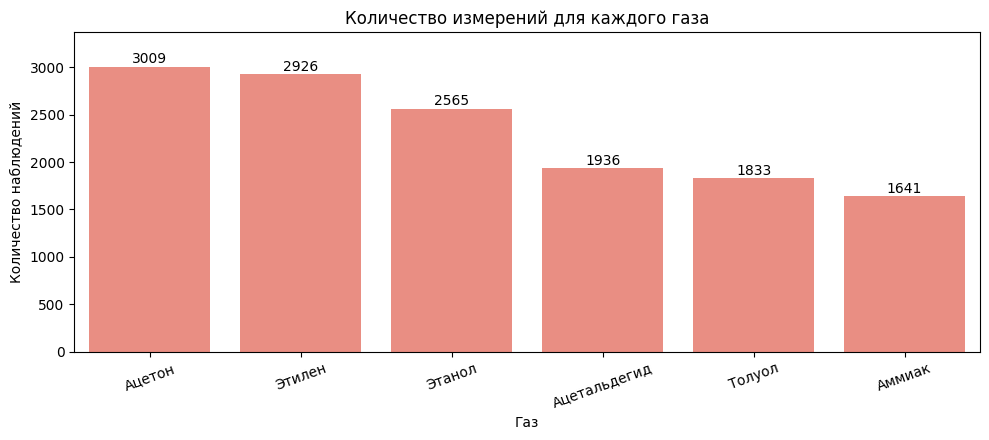

In [ ]:
gas_names = {
    1: "Этанол",
    2: "Этилен",
    3: "Аммиак",
    4: "Ацетальдегид",
    5: "Ацетон",
    6: "Толуол"
}
df["gas_id"] = df["gas_id"].astype(int)
gas_counts = (df["gas_id"]
              .value_counts()
              .rename(index = gas_names)
              .sort_values(ascending = False))


plt.figure(figsize= (10, 4.5))
ax = sns.barplot(
    x = gas_counts.index ,
    y = gas_counts.values,
    color = "salmon"
)

for i, value in enumerate(gas_counts.values):
  ax.text(
      i, value + 35,
      str(value),
      ha = "center",
      fontsize = 10
  )
plt.title("Количество измерений для каждого газа")
plt.xlabel("Газ")
plt.ylabel("Количество наблюдений")
plt.ylim(0, gas_counts.max() * 1.12)
plt.xticks(rotation = 20)
plt.tight_layout()
plt.show()


Но исходя из того, что написано в официальной документации Датасета [Gas Sensor Array Drift at Different Concentrations](https://archive.ics.uci.edu/dataset/270/gas%2Bsensor%2Barray%2Bdrift%2Bdataset%2Bat%2Bdifferent%2Bconcentrations?$0), получившиеся значения не соотетствуют тому, что есть в описании.


---


Проверим корректность проставления индексов. В описании указано следующее:


```
#  The first character (1-6) codes the analyte, followed by the concentration level:

1: Ethanol; 2: Ethylene; 3: Ammonia; 4: Acetaldehyde; 5: Acetone; 6: Toluene
```

---

Также указано количество измерений в каждом отдельном .dat файле:


```
Batch ID: Ethanol, Ethylene, Ammonia, Acetaldehyde, Acetone, Toluene

Batch 1: 83, 30, 70, 98, 90, 74

...

Batch 10: 600, 600, 600, 600, 600, 600
```
Сверим проставку индексов исходя из этого:




In [ ]:

print("Количество измерений в batch1:")
display(
    df[df["batch"] == 1]["gas_id"]
    .value_counts()
    .sort_index()
    .to_frame()
    .T
)


Количество измерений в batch1:


gas_id,1,2,3,4,5,6
count,90,98,83,30,70,74


Это не соотвествует описанию официальной документации, так что заменим индексацию газов на реальную, посмотрим ещё раз, какой газ имеет больше всего, сформируем выборку, очистим её и проанализруем.


---

Что получилось реально?


```
gas_id 1  2  3  4  5  6
count 90 98 83 30 70 74
```
Что было в документации?


```
Batch ID: Ethanol, Ethylene, Ammonia, Acetaldehyde, Acetone, Toluene

Batch 1: 83, 30, 70, 98, 90, 74
```
Следовательно, у нас следующие соответствия индексов и названий газов:


```
1: Ацетон
2: Ацетальдегид
3: Этанол
4: Этилен
5: Аммиак
6: Толуол
```


---
Для более глубокого анализа зависимостей (или независимостей) показаний датчиков выберем измерения, полученные только для одного газа - аммиака, так как для этого газа больше всего измерений.

Сформируем выборку из 2500 измерений (~83% от исходных данных для аммиака)






In [ ]:

gas_names = {
    1: "Ацетон",
    2: "Ацетальдегид",
    3: "Этанол",
    4: "Этилен",
    5: "Аммиак",
    6: "Толуол"
}



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ammonia = general[
    general["gas_id"] == 5
].copy()

ammonia["concentration"] = pd.to_numeric(
    ammonia["concentration"],
    errors="coerce"
)

ammonia["feature_1"] = pd.to_numeric(
    ammonia["feature_1"],
    errors="coerce"
)

ammonia = ammonia.dropna(
    subset=["concentration", "feature_1"]
).copy()

print("Количество наблюдений:", len(ammonia))
print(
    "Количество уникальных концентраций:",
    ammonia["concentration"].nunique()
)

display(ammonia.head())



quality_report = pd.DataFrame({
    "Показатель": [
        "Количество наблюдений",
        "Количество столбцов",
        "Пропущенные значения",
        "Бесконечные значения",
        "Полные дубликаты"
    ],
    "Значение": [
        len(sample),
        sample.shape[1],
        int(sample.isna().sum().sum()),
        int(np.isinf(numeric_data.to_numpy()).sum()),
        int(sample.duplicated().sum())
    ]
})

display(quality_report)




Количество наблюдений: 3009
Количество уникальных концентраций: 47


,batch,gas_id,concentration,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_119,feature_120,feature_121,feature_122,feature_123,feature_124,feature_125,feature_126,feature_127,feature_128
301,1,5,25.0,101302.8438,3.219995,6.738114,7.697570,11.678351,-11.431375,-14.430668,...,-0.631671,-1.194072,3348.9021,2.388075,0.257850,0.336342,0.981609,-0.415907,-0.563978,-1.130713
302,1,5,50.0,162506.7734,4.339669,15.022841,17.473256,18.237865,-22.744941,-29.061686,...,-1.315236,-1.833792,5762.2732,3.391119,0.499767,0.724584,1.869807,-0.866630,-1.169391,-1.568593
303,1,5,75.0,218882.8359,5.387921,25.567566,28.648708,33.000127,-33.771200,-42.738527,...,-2.299062,-2.866786,7990.4006,4.167752,0.865619,1.043460,1.393910,-1.464265,-2.051588,-3.680099
304,1,5,100.0,265655.9180,6.193402,36.058763,40.936774,51.267109,-43.157429,-55.428141,...,-3.321521,-3.829159,10174.7012,5.083164,1.240725,1.467667,2.167341,-2.012041,-2.857010,-3.283386
305,1,5,125.0,306461.9180,6.832140,47.235582,60.132712,176.958357,-51.751468,-66.831506,...,-4.251736,-4.721179,11976.2176,5.805632,1.616693,2.330211,2.522875,-2.534856,-3.659790,-4.170831


,Показатель,Значение
0,Количество наблюдений,2500
1,Количество столбцов,131
2,Пропущенные значения,0
3,Бесконечные значения,0
4,Полные дубликаты,0


Сформировали выборку из 10 тыс значений, проверили целостночть данных, проверили датасет на дубликаты, пропущенные значения, перемешали данные


**Выбор 3х случайных величин**

Как было сказано в описании датасета, в исходном датасете описаны электронные отклики, полученные с каждого сенсора (по 8 откликов с 16 сенсоров).

Для дальнейшего анализа выберем характеристики, которые не являются одной и той же характеристикой разных сенсоров (так как в таком случае возможен вариант зависимости этих величин).

Поэтому для анализа выберем:


*   X - feature_1 - Максимальное изменение отклика 1го сенсора
*   Y - feature_13 - Характеристика нарастания отклика для 2го сенсора
*   Z - feature_24 - Характеристика спада отклика для 3го сенсора.

Таким образом, величины описывают разные характеристики (дельта, нарастание и спад.), поэтому есть надежда получить более интересные данные и разные характеристики для каждой из характеристик.



In [ ]:

sensor_data = sample[
    ["feature_1", "feature_13", "feature_24"]
].copy()

sensor_data.columns = ["X", "Y", "Z"]

print("Размер исследуемой таблицы:", sensor_data.shape)
display(sensor_data.head(10))


Размер исследуемой таблицы: (2500, 3)


,X,Y,Z
3142,156913.3164,53.102125,-6.357711
3076,197653.6016,73.817222,-10.247952
9681,2.7356,46.821323,-14.713468
11909,105666.1797,65.265324,-12.491395
3623,177945.9101,92.946525,-20.466812
13803,182176.7227,158.304200,-60.495800
1376,274108.5117,116.860055,-14.622466
1520,84417.4336,26.128218,-2.580314
13551,23797.7031,15.471553,-3.932380
11881,156186.5782,95.848340,-22.360711


## Random Variable 01 — Maximum Sensor Response

### Describtion

В качестве 1-ой случайной величины было выбрано максимально изменения отклика первого сенсора - **feature_1**.



---

**Описание величины**

При воздействии газа на сенсоры электрическое сопростивление газочувствительной части датчика изменяется в ходе физико-химических процессов на его поверхности. Величина зависит от природы газа, его концентрации и других химических параметров.

Признак **feature_1** характериует амплитуду этого отклика(сопротивления)


---

**Стахостическая природа первой величины**

В рамках исследования случайный экперимент = равновероятный выбор одного наблюдения из экпериментарной выборки.

В нашем случае - максимальное сопротивления отклика сенсора. До первого наблюдения значение заранее неизвестно, поскольку в выборке представлены данные при различных условиях (с разными веществами, концентрациями, ..., исправностью датчиков)

Следовательно, X - случайная величина относительно вероятностного эксперимента. Однако стоит сказать, что физико-химически, возможно эту величину можно описать какой-то зависимостью.


---

Пркатическое обоснование этого факта:

In [ ]:

X = sample["feature_1"].copy()

print("Количество наблюдений:", X.count())
print("Количество уникальных значений:", X.nunique())
print("Минимальное значение:", X.min())
print("Максимальное значение:", X.max())
print("Выборочная дисперсия:", X.var())


Количество наблюдений: 2500
Количество уникальных значений: 2497
Минимальное значение: -124.0596
Максимальное значение: 670687.3477
Выборочная дисперсия: 10361890767.300941


### EDA & Distribution

Наконец-то переходим к вычислениям и анализу данных.

Для исследования случайной величины X определим статистические характеристики, среднее, медиану,  дисперсию, стандартное отклонение, квартили, ассиметрию и эксцесс.

Эти значения помогут определить положение и разброс значений, выявить особенности формы эмпирического распределения.

In [ ]:


stats_X = pd.Series({
    "Количество наблюдений": X.count(),
    "Среднее": X.mean(),
    "Медиана": X.median(),
    "Дисперсия": X.var(ddof=1),
    "Стандартное отклонение": X.std(ddof=1),
    "Минимум": X.min(),
    "Q1 (25%)": X.quantile(0.25),
    "Q3 (75%)": X.quantile(0.75),
    "IQR": X.quantile(0.75) - X.quantile(0.25),
    "Максимум": X.max(),
    "Асимметрия": X.skew(),
    "Эксцесс": X.kurt()
})

display(
    stats_X.to_frame(name="Значение")
    .style.format("{:,.2f}", thousands=" ", decimal=",")
)


,Значение
Количество наблюдений,"2 500,00"
Среднее,"127 868,96"
Медиана,"117 199,75"
Дисперсия,"10 361 890 767,30"
Стандартное отклонение,"101 793,37"
Минимум,"-124,06"
Q1 (25%),"51 494,30"
Q3 (75%),"198 474,34"
IQR,"146 980,04"
Максимум,"670 687,35"


По этим значениям для выборки очень сложно сказать что-то конкретное, так как дисперсия и среднее отклонение довольно большое. Этот отклик для 1го сенсора очень чувствителен ко всем параметрам химической системы, хотя в выборке у нас находятся данные только по одному газу.

Среднее значение значительно превышает медиану, что указывает на влияние крупных положительных значений. Стандартное отклонение составляет 101 793,37, а центральные 50% наблюдений находятся в интервале от 51 494,30 до 198 474,34.

Коэффициент ассиметрии составляет 1,12, что указывает о правосторонней симметрии распределения.

Таким образом, отлики данного сенсора имеют довольно большой разброс, возможно на это влияет различие концентрации газа и различие экспериментальных партий.


---

Визуализация:

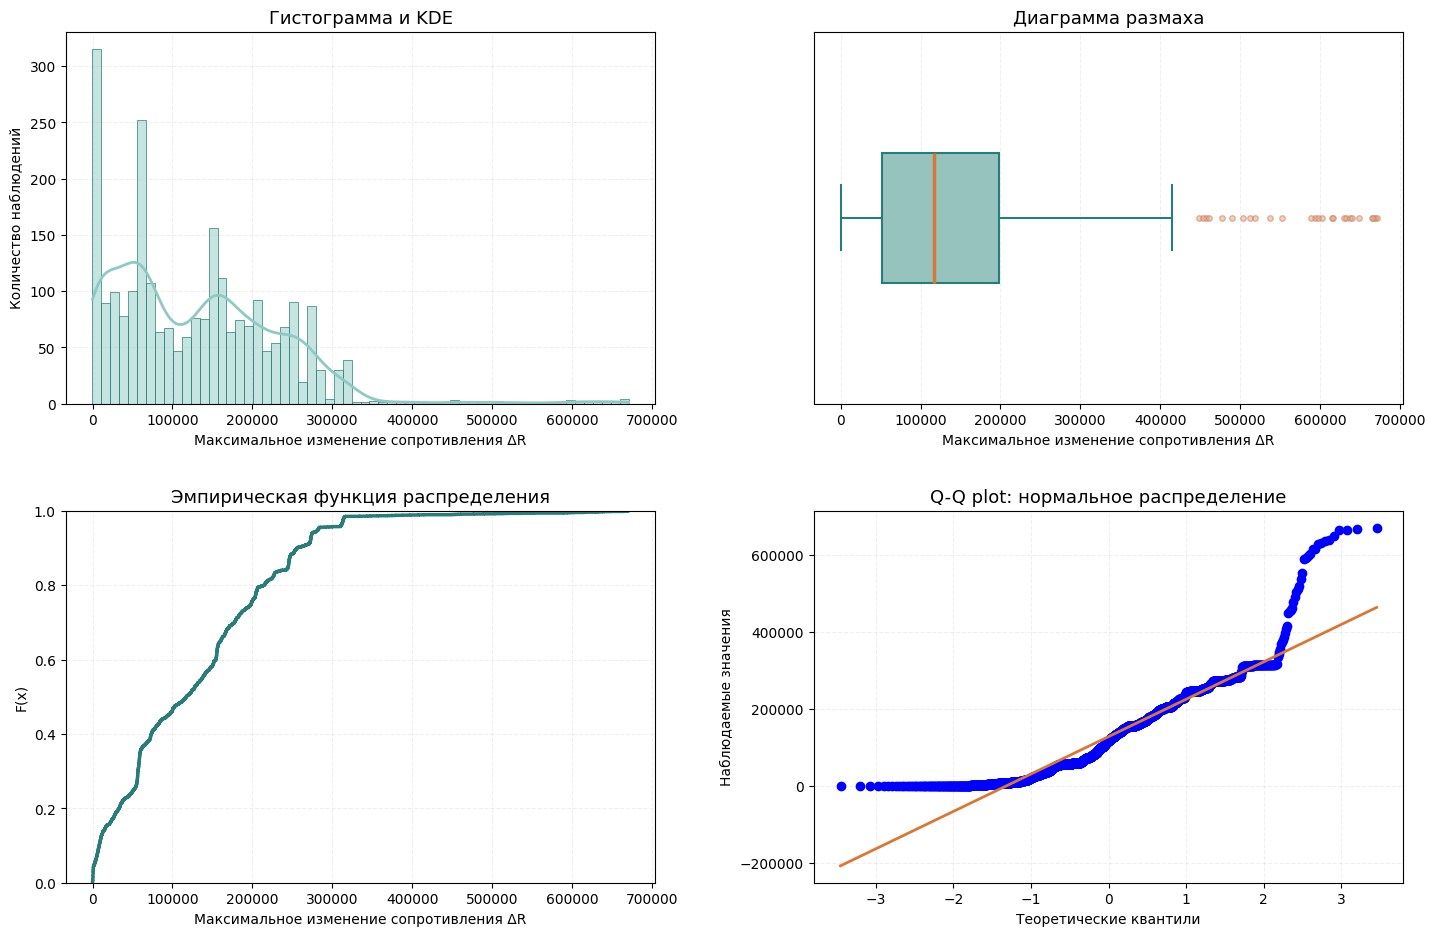

In [ ]:


fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(
    X,
    bins=60,
    kde=True,
    color="#8ECAC3",
    edgecolor="#287D78",
    linewidth=0.5,
    line_kws={"color": "#D97735", "linewidth": 2},
    ax=axes[0, 0]
)

axes[0, 0].set_title("Гистограмма и KDE", fontsize=13)
axes[0, 0].set_xlabel("Максимальное изменение сопротивления ΔR")
axes[0, 0].set_ylabel("Количество наблюдений")


sns.boxplot(
    x=X,
    ax=axes[0, 1],
    color="#8ECAC3",
    width=0.35,
    linewidth=1.5,
    boxprops={"edgecolor": "#287D78"},
    medianprops={"color": "#D97735", "linewidth": 2.5},
    whiskerprops={"color": "#287D78", "linewidth": 1.5},
    capprops={"color": "#287D78", "linewidth": 1.5},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#E5A37E",
        "markeredgecolor": "#C47C59",
        "markersize": 4,
        "alpha": 0.5
    }
)

axes[0, 1].set_title("Диаграмма размаха", fontsize=13)
axes[0, 1].set_xlabel("Максимальное изменение сопротивления ΔR")
axes[0, 1].set_ylabel("")
axes[0, 1].set_yticks([])


sns.ecdfplot(
    x=X,
    color="#287D78",
    linewidth=2.5,
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Эмпирическая функция распределения",
    fontsize=13
)
axes[1, 0].set_xlabel("Максимальное изменение сопротивления ΔR")
axes[1, 0].set_ylabel("F(x)")

stats.probplot(
    X,
    dist="norm",
    plot=axes[1, 1]
)

qq_ax = axes[1, 1]



qq_ax.get_lines()[1].set_color("#D97735")
qq_ax.get_lines()[1].set_linewidth(2)

qq_ax.set_title("Q-Q plot: нормальное распределение", fontsize=13)
qq_ax.set_xlabel("Теоретические квантили")
qq_ax.set_ylabel("Наблюдаемые значения")



for ax in axes.flat:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=10)

plt.tight_layout(pad=3)
plt.show()


Попробуем описать то, что получилось:

1) Гистограмма KDE

По этому графику видно: во-первых, положительная ассиметрия, во-вторых, основная часть измерений  сосредоточена в диапазоне от 0 до 300000, некоторые значения достигают ~600000, в-третьих, на гистограмме выделяются несколько выраженных пиков пиков, что также видно по линии KDE.

2) Диаграмма размаха.

Диаграмма показывает вариативность откликов сенсора, средний диапазон примерно ~50 - 200 тыс.  Правая часть(та, что за медианой) значительно больше левой. Также видны выбросы, значения которых достигают до 700000

3) Эмпирическая функция распределения.

Функция возрастает неравномерно, есть отдельные участки с более резким подъемом.

4) Q-Q plot

На этом графики существенно расходятся эмпирические значения от теоретических. Особенно выражены отклонения в нижнем и верхнем хвостам


Небольшой вывод:

Все эти визуализации указывают на неоднородность данных, что и понятно, так как в химической системе много параметров, которые могут влиять на покащания сенсоров.


Для объяснения этих особенностей, нужно посмотреть на зависимось этой величины от концентрации газа.

Посмотрим как зависит концентрация газа на показания сенсора:

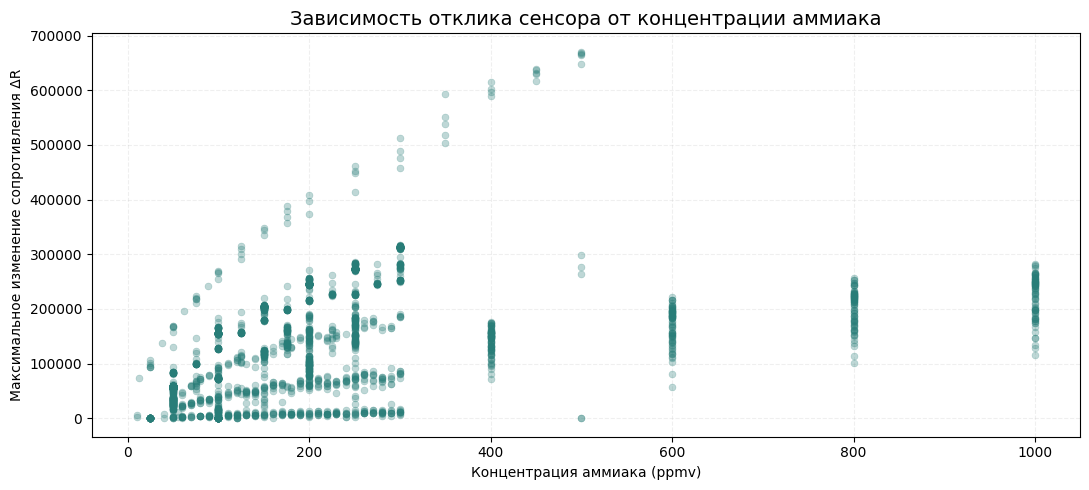

In [ ]:

eda_conc = sample[
    ["concentration", "feature_1"]
].copy()

eda_conc["concentration"] = pd.to_numeric(
    eda_conc["concentration"],
    errors="coerce"
)

eda_conc = eda_conc.dropna()

fig, ax = plt.subplots(figsize=(11, 5))

sns.scatterplot(
    data=eda_conc,
    x="concentration",
    y="feature_1",
    color="#287D78",
    alpha=0.3,
    s=25,
    edgecolor=None,
    ax=ax
)

ax.set_title(
    "Зависимость отклика сенсора от концентрации аммиака",
    fontsize=14
)
ax.set_xlabel("Концентрация аммиака (ppmv)")
ax.set_ylabel("Максимальное изменение сопротивления ΔR")

ax.grid(alpha=0.2, linestyle="--")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Вот теперь мы видимо объяснение странных пиков на гистограмме с KDE. Теперь у нас есть возможное объяснение необычной гистограммы.

Ранее мы обнаружили несколько областей повышенной плотности, правостороннюю асимметрию и большие положительные значения.

Диаграмма рассеяния показывает, что данные состоят из нескольких различающихся групп откликов. Причём различия наблюдаются даже при одинаковой концентрации аммиака.

Таким образом, неоднородность распределения может быть связана не только с концентрацией, но и с другими условиями измерения.

Это пока гипотеза, которую мы проверим дальше.

**Попробуем посмотреть сильно ли различаются показания из разных групп**

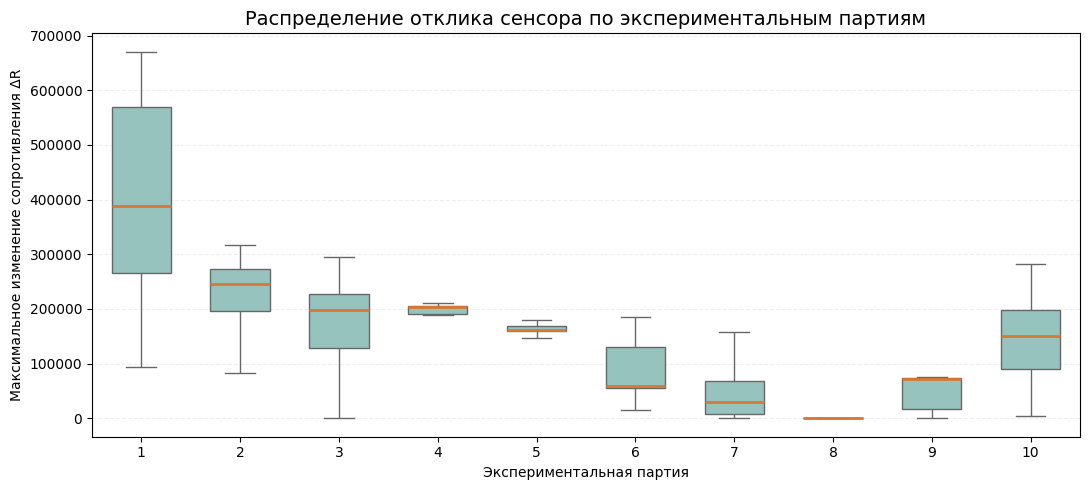

In [ ]:

fig, ax = plt.subplots(figsize=(11, 5))

sns.boxplot(
    data=sample,
    x="batch",
    y="feature_1",
    color="#8ECAC3",
    width=0.6,
    showfliers=False,
    medianprops={
        "color": "#D97735",
        "linewidth": 2
    },
    ax=ax
)

ax.set_title(
    "Распределение отклика сенсора по экспериментальным партиям",
    fontsize=14
)
ax.set_xlabel("Экспериментальная партия")
ax.set_ylabel("Максимальное изменение сопротивления ΔR")

ax.grid(axis="y", alpha=0.2, linestyle="--")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


По этой диаграмме распределения мы видим почему в самой первой гистограмме по этой величине у нас были такие странные пики и волны. **Разные партии имеют разные характерные значения отклика нашего сенсора**.


---

Теперь сравним значений из разныз партий для одной концентрации

In [ ]:

check = sample[
    ["batch", "concentration", "feature_1"]
].copy()

check["concentration"] = pd.to_numeric(
    check["concentration"],
    errors="coerce"
)

common_conc = (
    check.groupby("concentration")
    .agg(
        наблюдений=("feature_1", "count"),
        партий=("batch", "nunique")
    )
    .query("партий >= 2")
    .sort_values(
        ["партий", "наблюдений"],
        ascending=False
    )
)

display(common_conc.head(15))


,наблюдений,партий
concentration,,
100.0,291,7
200.0,253,7
50.0,412,6
250.0,232,6
150.0,180,5
300.0,130,4
175.0,84,4
75.0,34,4
25.0,48,3


Мы выяснили какой концентрации больше всего во всех частях датасета. Теперь посмотрим их зависимости

,Количество,Среднее,Медиана,Стандартное_отклонение
batch,,,,
1,4,264125.20,266347.53,6124.56
2,86,157732.63,155514.95,4802.82
3,28,93662.40,127472.05,58481.86
6,10,78664.14,89831.32,22386.82
7,26,28986.81,31285.76,27410.77
8,70,3527.76,755.04,5888.73
9,67,51776.02,72400.45,29274.13


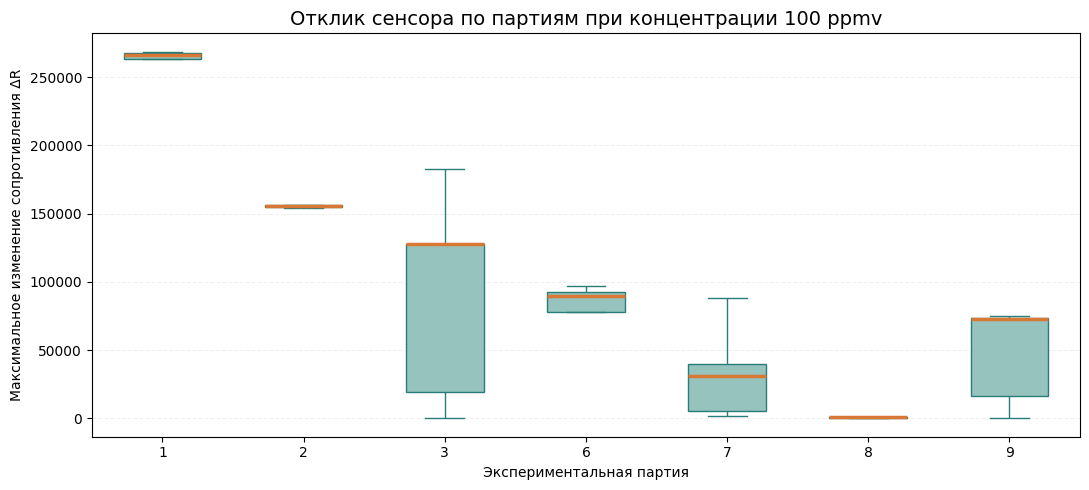

In [ ]:


data_100 = sample.copy()

data_100["concentration"] = pd.to_numeric(
    data_100["concentration"],
    errors="coerce"
)


data_100 = data_100[
    data_100["concentration"] == 100
].copy()


batch_stats = (
    data_100.groupby("batch")["feature_1"]
    .agg(
        Количество="count",
        Среднее="mean",
        Медиана="median",
        Стандартное_отклонение="std"
    )
    .round(2)
)

display(batch_stats)

fig, ax = plt.subplots(figsize=(11, 5))

sns.boxplot(
    data=data_100,
    x="batch",
    y="feature_1",
    color="#8ECAC3",
    width=0.55,
    showfliers=False,
    boxprops={"edgecolor": "#287D78"},
    medianprops={"color": "#D97735", "linewidth": 2.5},
    whiskerprops={"color": "#287D78"},
    capprops={"color": "#287D78"},
    ax=ax
)

ax.set_title(
    "Отклик сенсора по партиям при концентрации 100 ppmv",
    fontsize=14
)
ax.set_xlabel("Экспериментальная партия")
ax.set_ylabel("Максимальное изменение сопротивления ΔR")

ax.grid(axis="y", alpha=0.2, linestyle="--")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Вот мы нашли почему наши данные так сильно отличаются. При разных условиях сенсор откликается совсем по разному даже на одну концентрацию. Медианные значения из каждой партии слишком сильно отличаются. Эти данные показывают, что концентрация исхожного газа не может полностью объяснить неоднородность откликов сенсора.

**Перейдем к нормализации **

Среднее: 0.0
Стандартное отклонение: 1.0


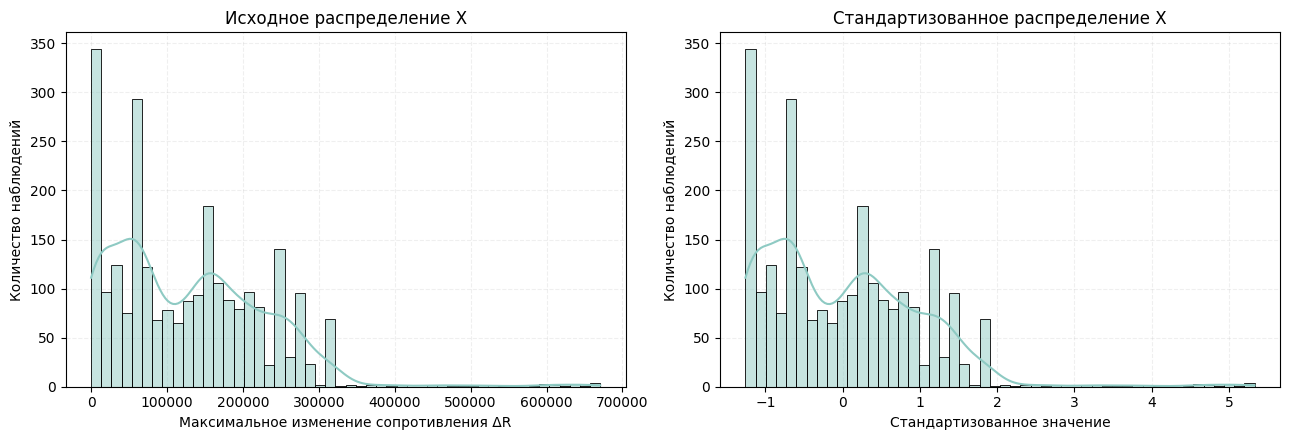

In [ ]:

X_standardized = (X - X.mean()) / X.std(ddof=1)

print("Среднее:", round(X_standardized.mean(), 6))
print("Стандартное отклонение:",
      round(X_standardized.std(ddof=1), 6))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(
    X, bins=50, kde=True,
    color="#8ECAC3",
    ax=axes[0]
)
axes[0].set_title("Исходное распределение X")
axes[0].set_xlabel("Максимальное изменение сопротивления ΔR")
axes[0].set_ylabel("Количество наблюдений")

sns.histplot(
    X_standardized, bins=50, kde=True,
    color="#8ECAC3",
    ax=axes[1]
)
axes[1].set_title("Стандартизованное распределение X")
axes[1].set_xlabel("Стандартизованное значение")
axes[1].set_ylabel("Количество наблюдений")

for ax in axes:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Для приведения значений случайной величины к единомц масштабу была применена нормализация/стандартизация z-score. Каждое значение  преобразуется путем вычитания выборочного среднего и деление на выборочное стандартное отклонение.

**Исследуем теоретическое распределение. **

Для оценки возможности описания случайной величины X теоретическим законом распределения было проведено сравнение эмпирической плотности с плотностью нормального распределения.

Параметры нормальной модели оценивались по экспериментальной выборке: математическое ожидание — выборочным средним, стандартное отклонение — соответствующей выборочной оценкой.

В качестве начальной модели выбрано нормальное распределение, поскольку оно позволяет оценить отклонения экспериментальных данных от симметричного распределения и служит базой для дальнейшего сравнения альтернативных моделей.

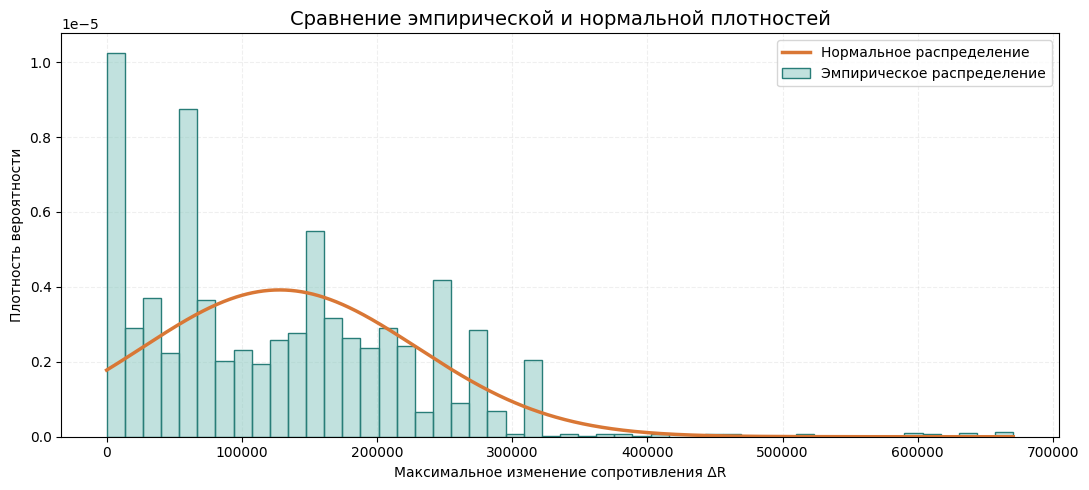

In [ ]:



mu = X.mean()
sigma = X.std(ddof=1)

# Значения для теоретической кривой
x_grid = np.linspace(X.min(), X.max(), 1000)

normal_pdf = stats.norm.pdf(
    x_grid,
    loc=mu,
    scale=sigma
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    X,
    bins=50,
    stat="density",
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.55,
    ax=ax,
    label="Эмпирическое распределение"
)

# Теоретическая плотность
ax.plot(
    x_grid,
    normal_pdf,
    color="#D97735",
    linewidth=2.5,
    label="Нормальное распределение"
)

ax.set_title(
    "Сравнение эмпирической и нормальной плотностей",
    fontsize=14
)
ax.set_xlabel("Максимальное изменение сопротивления ΔR")
ax.set_ylabel("Плотность вероятности")

ax.legend()
ax.grid(alpha=0.2, linestyle="--")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


По графику видно, что нормальное теоретическое распределение совершенно не соответствует экспериментальным данным. Гладкая и симметричная нормальная кривая никак не отражает довольно заметных пиков в области небольших значений.

Таким образом, нормальное распределение не является хорошей моделью для описания все выборки X.  Но полученный результат согласуется с выявленной положительной ассиметрией.

В связи с тем, что нормальное симметричное распределение совершенно не соответствует экспериментальным данным, можно проверить асимметричное распределение.

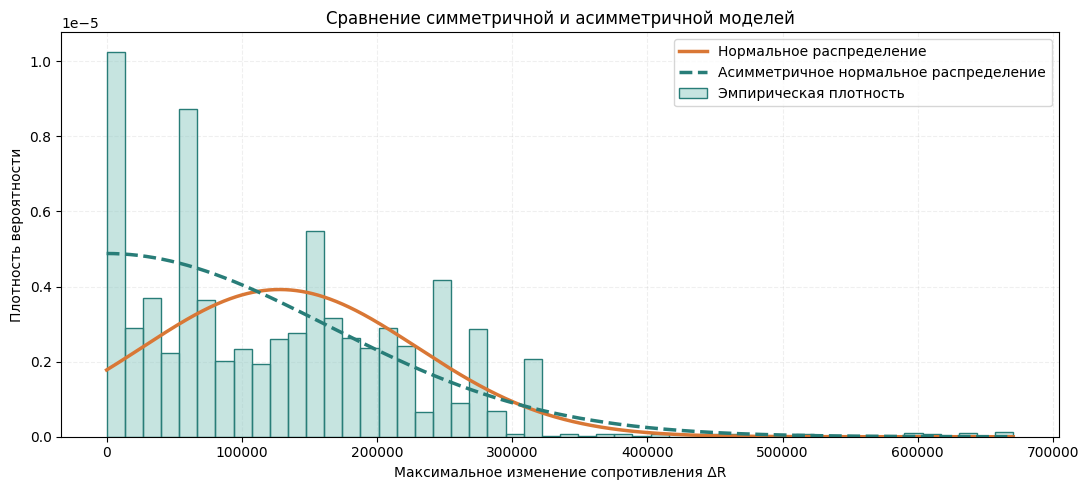

Параметры skewnorm: (np.float64(508428887.33620644), np.float64(-124.06111442239296), np.float64(163522.21750065056))


In [ ]:


x_values = X.dropna().to_numpy()

# Подбираем параметры распределений
normal_params = stats.norm.fit(x_values)
skew_params = stats.skewnorm.fit(x_values)

# Сетка значений
x_grid = np.linspace(
    x_values.min(),
    x_values.max(),
    1000
)

# Плотности
normal_pdf = stats.norm.pdf(x_grid, *normal_params)
skew_pdf = stats.skewnorm.pdf(x_grid, *skew_params)

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    x_values,
    bins=50,
    stat="density",
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.5,
    label="Эмпирическая плотность",
    ax=ax
)

ax.plot(
    x_grid,
    normal_pdf,
    color="#D97735",
    linewidth=2.5,
    label="Нормальное распределение"
)

ax.plot(
    x_grid,
    skew_pdf,
    color="#287D78",
    linewidth=2.5,
    linestyle="--",
    label="Асимметричное нормальное распределение"
)

ax.set_title("Сравнение симметричной и асимметричной моделей")
ax.set_xlabel("Максимальное изменение сопротивления ΔR")
ax.set_ylabel("Плотность вероятности")

ax.legend()
ax.grid(alpha=0.2, linestyle="--")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("Параметры skewnorm:", skew_params)


Сравнение показало, что асимметричная нормальная модель лучше отражает общую форму эмпирического распределения, поскольку учитывает положительную асимметрию и наличие протяжённого правого хвоста.

Однако обе модели не воспроизводят отдельные скопления наблюдений и экстремально большие значения отклика сенсора.

### Independence & Estimations

Чтобы исследовать зависимости и независимости величины, начнем с того, что посмотрим на зависимости всех 3х случаныйных величин. Для следующих случайных величин такое делать не будем, сделаем такое один раз здесь. Для этого пстроим 3 диаграммы рассеяния и матрица корреляции.

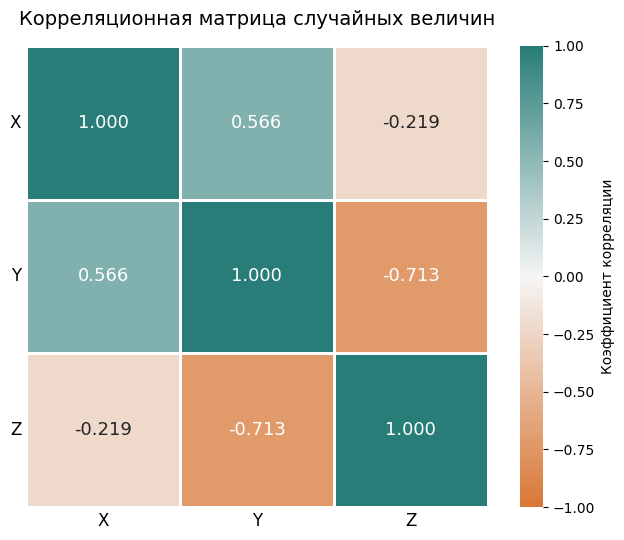

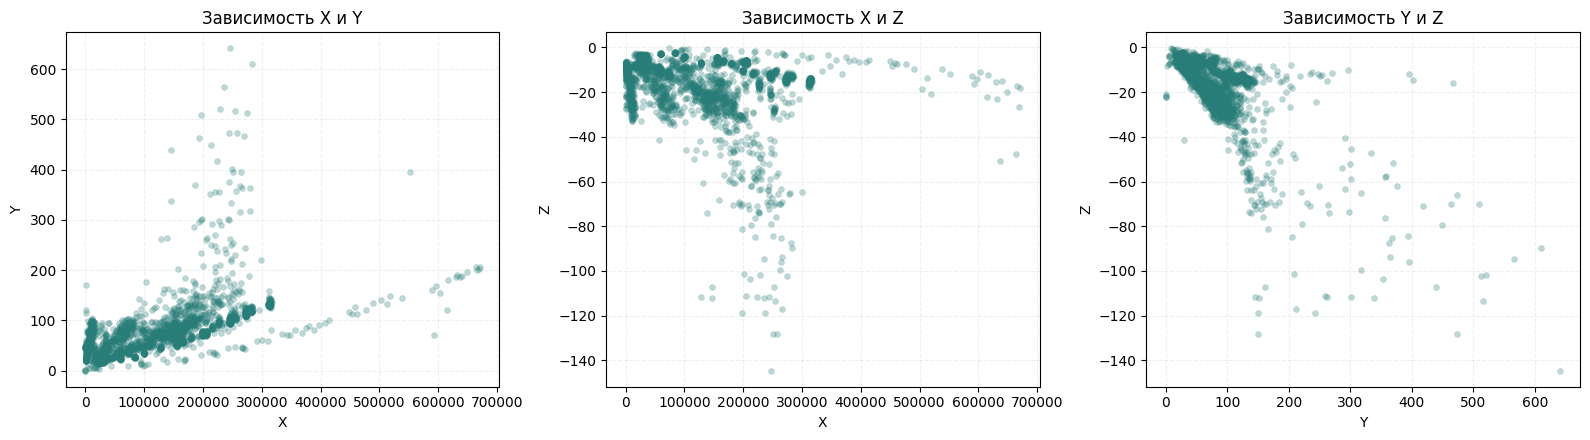

In [ ]:


sensor_data = sample[
    ["feature_1", "feature_13", "feature_24"]
].dropna().copy()

sensor_data.columns = ["X", "Y", "Z"]


import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

corr_matrix = sensor_data[["X", "Y", "Z"]].corr()

colors = ["#D97735", "#F5F5F5", "#287D78"]
cmap = LinearSegmentedColormap.from_list(
    "correlation_palette", colors
)

fig, ax = plt.subplots(figsize=(7, 5.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap=cmap,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=2,
    linecolor="white",
    annot_kws={"size": 13},
    cbar_kws={"label": "Коэффициент корреляции"},
    ax=ax
)

ax.set_title(
    "Корреляционная матрица случайных величин",
    fontsize=14,
    pad=15
)

ax.tick_params(axis="both", length=0, labelsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()


#display(corr_matrix.round(3))


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

pairs = [("X", "Y"), ("X", "Z"), ("Y", "Z")]

for ax, (a, b) in zip(axes, pairs):
    sns.scatterplot(
        data=sensor_data,
        x=a,
        y=b,
        color="#287D78",
        alpha=0.3,
        s=18,
        edgecolor=None,
        ax=ax
    )

    ax.set_title(f"Зависимость {a} и {b}")
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Что видно по построенным графиках и матрице:

Хоть величины выбирались абсолютно случайно, между величинами X и Y обнаружена положительная корреляция, что указывает наа тендецию к совместному увеличению значений данных характеристик.

Связь между X и Z значительно слабее

Наиболее выраженная корреляция установлена между Y и Z (r = −0,713). Это свидетельствует о достаточно сильной отрицательной линейной связи между характеристиками нарастания и спада сенсорных откликов.



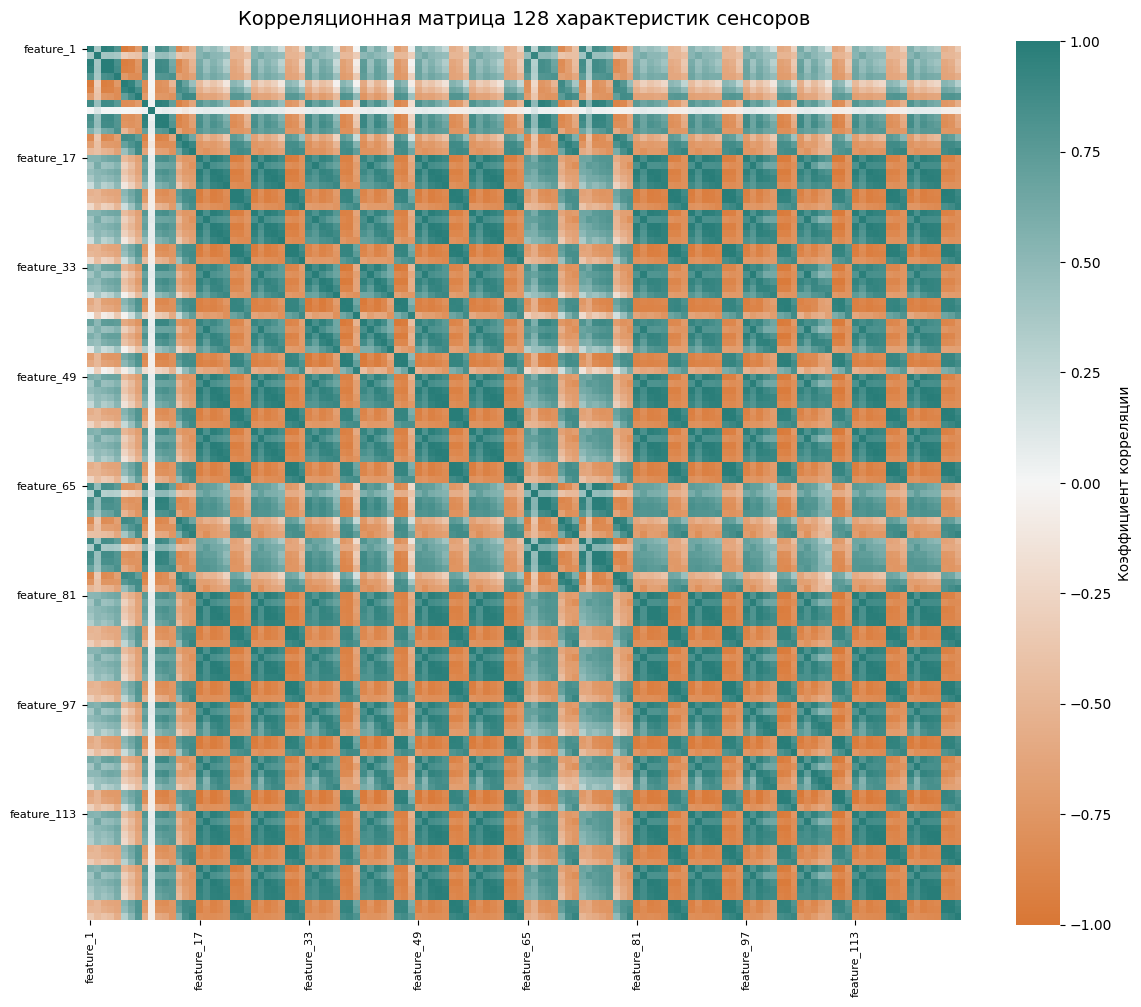

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

features = [f"feature_{i}" for i in range(1, 129)]

corr_all = sample[features].corr(method="pearson")

# Цветовая палитра
cmap = LinearSegmentedColormap.from_list(
    "correlation_palette",
    ["#D97735", "#F5F5F5", "#287D78"]
)

# Тепловая карта
fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    corr_all,
    cmap=cmap,
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    xticklabels=16,
    yticklabels=16,
    square=True,
    cbar_kws={"label": "Коэффициент корреляции"},
    ax=ax
)

ax.set_title(
    "Корреляционная матрица 128 характеристик сенсоров",
    fontsize=14,
    pad=15
)

ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.tick_params(axis="y", rotation=0, labelsize=8)

plt.tight_layout()
plt.show()


Также из любопытства была сделана корреляционная матрица по всей выборке.

По этой матрице хорошо видна блочная структура, обусловленная таким набором данных(16 сенсоров по 8 характеристик).


Выявлены области как положительных, так и отрицательных корреляций. Повторение цветовых структур указывает на сходные закономерности взаимосвязей между отдельными характеристиками разных сенсоров.

Таким образом, признаки сенсорного массива не являются полностью независимыми по линейным связям и могут содержать частично пересекающуюся информацию.

**Дальше почмотрим зависимость размера выборки на свойства EDA и не только**

Чтобы это выяснить, рассмотрим выборки разного объёма и проследим, как меняются оценки математического ожидания и дисперсии при увеличении числа наблюдений.

Также сравним два способа формирования выборки: с возвращением и без возвращения. Это позволит оценить, насколько способ отбора влияет на полученные результаты.

Размер совокупности: 3009
Среднее совокупности: 128,389.03
Дисперсия совокупности: 10,155,274,568.56


,n,Метод,Среднее оценок,SD среднего,Средняя дисперсия,SD дисперсии
0,20,Без возвращения,129518.77,22967.24,1.000229e+10,4.650800e+09
1,20,С возвращением,127558.21,22628.24,1.073130e+10,5.809757e+09
2,50,Без возвращения,129142.04,14620.05,1.053859e+10,3.495701e+09
3,50,С возвращением,128237.15,14503.69,1.004470e+10,3.275354e+09
4,100,Без возвращения,127652.58,10344.03,1.008321e+10,2.081071e+09
5,100,С возвращением,127408.35,10809.65,1.006696e+10,2.269918e+09
6,200,Без возвращения,129002.65,6683.87,1.036564e+10,1.512309e+09
7,200,С возвращением,128619.61,6782.10,1.018346e+10,1.514852e+09
8,500,Без возвращения,128574.99,4138.47,1.019942e+10,8.288900e+08
9,500,С возвращением,128217.84,4225.58,1.017041e+10,9.558306e+08


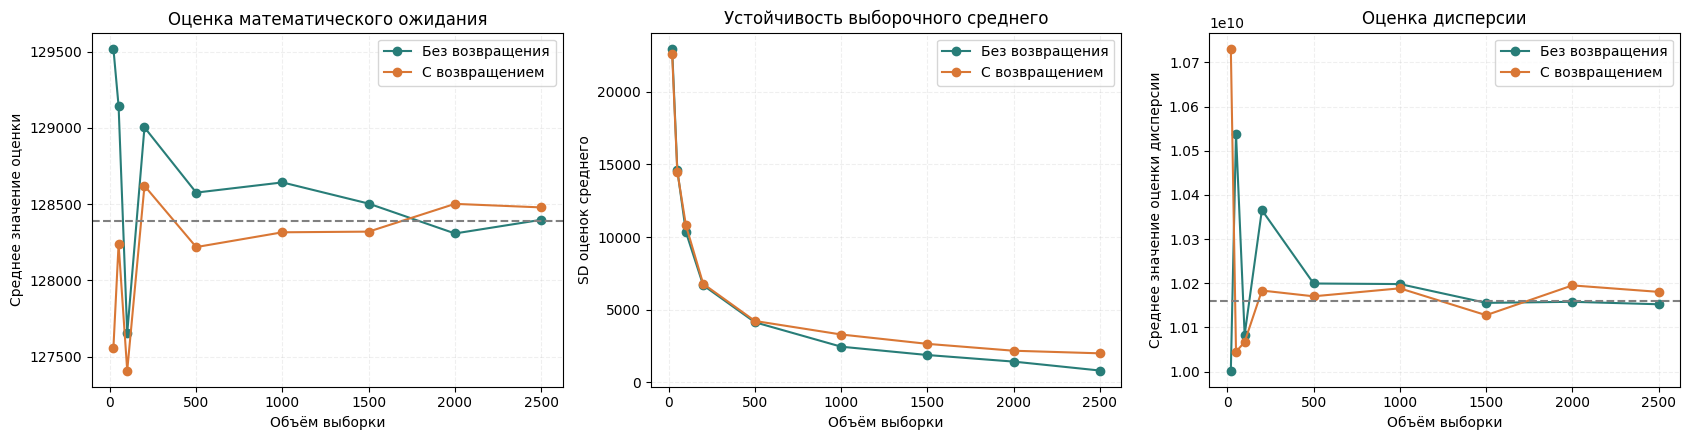

Выборочное среднее: 127,868.96
Стандартная ошибка: 837.47
95% доверительный интервал: [126,226.75; 129,511.16]


In [ ]:


# Полная доступная совокупность измерений аммиака
population_X = pd.to_numeric(
    general.loc[general["gas_id"] == 5, "feature_1"],
    errors="coerce"
).dropna().to_numpy()

# Основная выборка
x = X.dropna().to_numpy()

# Параметры конечной совокупности
mu_pop = population_X.mean()
var_pop = population_X.var(ddof=0)

print(f"Размер совокупности: {len(population_X)}")
print(f"Среднее совокупности: {mu_pop:,.2f}")
print(f"Дисперсия совокупности: {var_pop:,.2f}")

# Размеры выборок
sizes = np.array([20, 50, 100, 200, 500, 1000, 1500, 2000, 2500])

# Повторяем отбор 300 раз для каждого размера
repeats = 300
rng = np.random.default_rng(42)

results = []

for n in sizes:
    for replace in [False, True]:
        means = []
        variances = []

        for _ in range(repeats):
            selected = rng.choice(
                population_X,
                size=n,
                replace=replace
            )

            means.append(selected.mean())
            variances.append(selected.var(ddof=1))

        results.append({
            "n": n,
            "Метод": "С возвращением" if replace else "Без возвращения",
            "Среднее оценок": np.mean(means),
            "SD среднего": np.std(means, ddof=1),
            "Средняя дисперсия": np.mean(variances),
            "SD дисперсии": np.std(variances, ddof=1)
        })

results_df = pd.DataFrame(results)

display(results_df.round(2))


# Исправленная дисперсия конечной совокупности
var_ref = population_X.var(ddof=1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

palette = {
    "Без возвращения": "#287D78",
    "С возвращением": "#D97735"
}

# График 1. Средняя оценка матожидания
for method, group in results_df.groupby("Метод"):
    axes[0].plot(
        group["n"],
        group["Среднее оценок"],
        marker="o",
        color=palette[method],
        label=method
    )

axes[0].axhline(mu_pop, color="gray", linestyle="--")
axes[0].set_title("Оценка математического ожидания")
axes[0].set_xlabel("Объём выборки")
axes[0].set_ylabel("Среднее значение оценки")


# График 2. Разброс оценок среднего
for method, group in results_df.groupby("Метод"):
    axes[1].plot(
        group["n"],
        group["SD среднего"],
        marker="o",
        color=palette[method],
        label=method
    )

axes[1].set_title("Устойчивость выборочного среднего")
axes[1].set_xlabel("Объём выборки")
axes[1].set_ylabel("SD оценок среднего")


# График 3. Оценка дисперсии
for method, group in results_df.groupby("Метод"):
    axes[2].plot(
        group["n"],
        group["Средняя дисперсия"],
        marker="o",
        color=palette[method],
        label=method
    )

axes[2].axhline(var_ref, color="gray", linestyle="--")
axes[2].set_title("Оценка дисперсии")
axes[2].set_xlabel("Объём выборки")
axes[2].set_ylabel("Среднее значение оценки дисперсии")

for ax in axes:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend()

plt.tight_layout()
plt.show()



N = len(population_X)
n = len(x)

mean_x = x.mean()
std_x = x.std(ddof=1)

# Стандартная ошибка с поправкой
se = (std_x / np.sqrt(n)) * np.sqrt((N - n) / (N - 1))

# Приближённый 95% доверительный интервал
critical = stats.t.ppf(0.975, df=n - 1)

ci_lower = mean_x - critical * se
ci_upper = mean_x + critical * se

print(f"Выборочное среднее: {mean_x:,.2f}")
print(f"Стандартная ошибка: {se:,.2f}")
print(f"95% доверительный интервал: [{ci_lower:,.2f}; {ci_upper:,.2f}]")


Для проверки устойчивости мат ожидания и дисперсии были рассмотрены выборки различныго объема с возвращением и без.

Рещультаты показали, что при увеличении числа наблюдений разброс выборочныз оценок уменьшается, что собственно логично. Это отчетливо видно на графике отлонения выборочного среднего

При сравнении методов установлено, что для больших объёмов выборки отбор без возвращения обеспечивает меньшую изменчивость оценок среднего. Аналогичная тенденция наблюдается и для оценок дисперсии.

Дополнительно был рассчитан приближённый 95%-й доверительный интервал для математического ожидания, который составил от 126 226,75 до 129 511,16 при выборочном среднем 127 868,96.


## Random Variable 02 — Y

### Describtion

В качестве второй случайной величины выбрана характеристика нарастания отклика уже второго газового сенсора.

В отличае от первой величины, эта отражает не амплитуду изменения, а особенности сигнала сенсора на этапе его нарастания.

Случайной величиной (Y) будем считать значение данного признака для случайно выбранного измерения аммиака из исследуемой совокупности. Изменчивость значений может быть связана с концентрацией газа, экспериментальной партией и особенностями отклика сенсора.


---

**Стахостатическая природа величины**

В рамках исследования случайный эксперимент — это равновероятный выбор одного наблюдения из экспериментальной выборки.

В нашем случае Y характеризует нарастание отклика второго сенсора, рассчитанное методом экспоненциального скользящего среднего (EMAi, α = 0,1).

До выбора наблюдения значение Y неизвестно, поскольку измерения проводились при разных концентрациях аммиака, в различных экспериментальных партиях и условиях.

Следовательно, Y является случайной величиной относительно данного эксперимента. Однако с физико-химической точки зрения её значения могут подчиняться определённым закономерностям.

### EDA & Distribution

Для первоначального анализа случайной величины Y рассчитаем основные описательные статистики: выборочное среднее, медиану, дисперсию, стандартное отклонение, квартили, асимметрию и эксцесс.

Это позволит оценить характерные значения отклика второго сенсора, степень их разброса и предварительно определить особенности распределения.

In [ ]:

Y = sample["feature_13"].dropna().copy()

stats_Y = pd.Series({
    "Количество наблюдений": Y.count(),
    "Среднее": Y.mean(),
    "Медиана": Y.median(),
    "Дисперсия": Y.var(ddof=1),
    "Стандартное отклонение": Y.std(ddof=1),
    "Минимум": Y.min(),
    "Q1 (25%)": Y.quantile(0.25),
    "Q3 (75%)": Y.quantile(0.75),
    "IQR": Y.quantile(0.75) - Y.quantile(0.25),
    "Максимум": Y.max(),
    "Асимметрия": Y.skew(),
    "Эксцесс": Y.kurt()
})

display(
    stats_Y.to_frame(name="Значение").style.format(
        "{:,.2f}",
        thousands=" ",
        decimal=","
    )
)


,Значение
Количество наблюдений,"2 500,00"
Среднее,"77,39"
Медиана,"70,61"
Дисперсия,"3 343,25"
Стандартное отклонение,"57,82"
Минимум,"0,00"
Q1 (25%),"40,51"
Q3 (75%),"96,62"
IQR,"56,11"
Максимум,"641,18"


Эти данные совершенно отличаются от тех, которые мы получили в исследовании 1ой величины.

Во-первых, Ассиметрия 3,66 означает, что у распределения очень большой хвост в больших значениях, то есть большинство откликов сравнительно небольшие, но есть много больших выбросов, что как раз и показывает различие среднего и медианы.

Эксцесс 21,95 существенно превышает значение нормального распределения. Это говорит о сильном влиянии крайних наблюдений на четвёртый стандартизованный момент.



---

Для более понятной картины рассмотрим уже 4 графика EDA

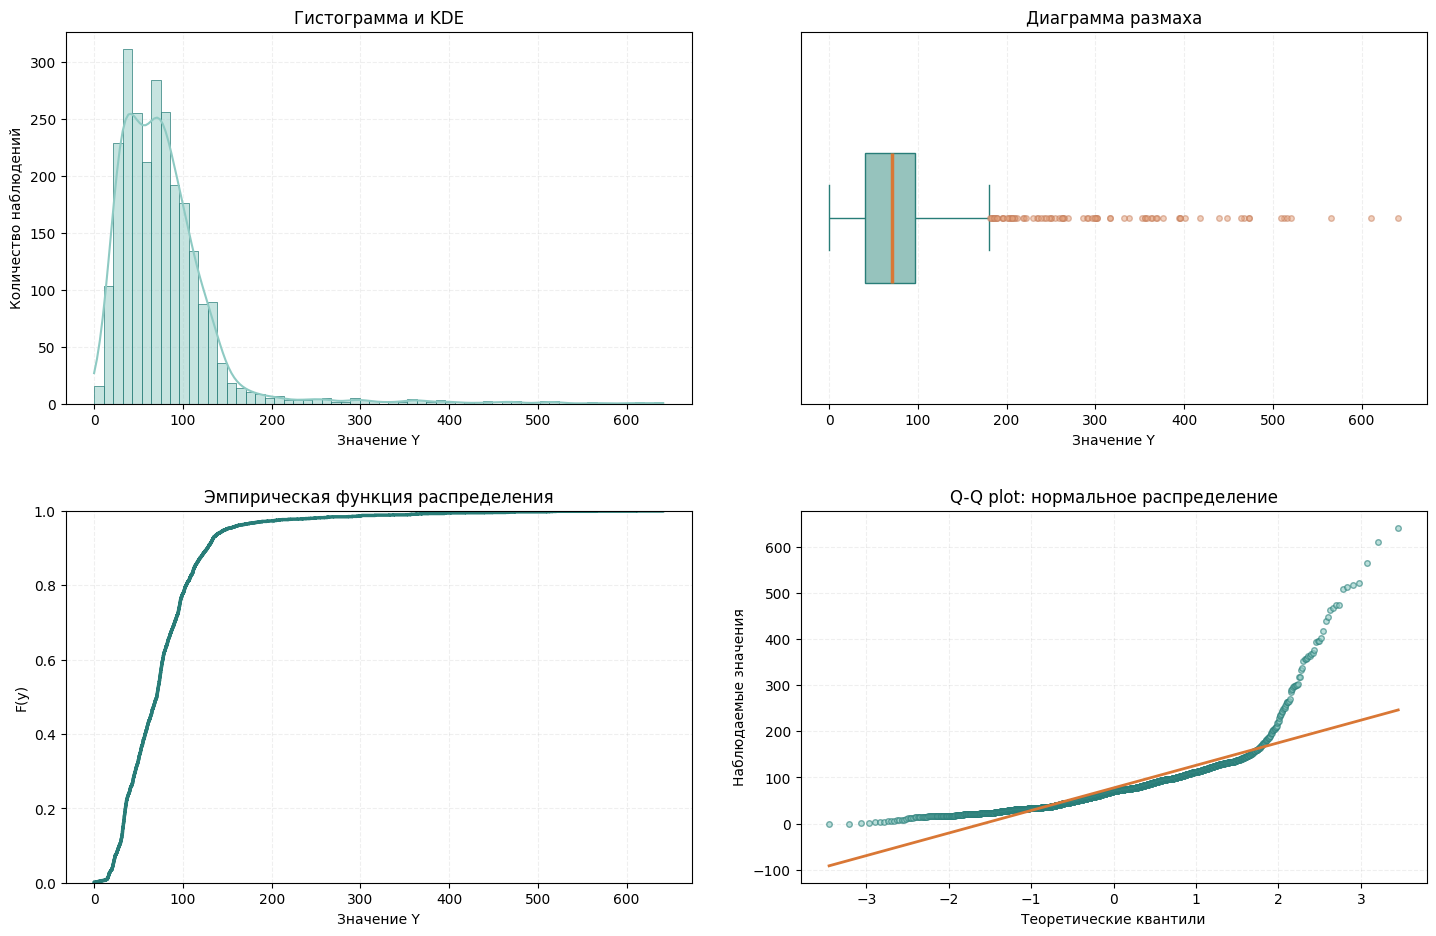

In [ ]:


fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Гистограмма и KDE
sns.histplot(
    Y,
    bins=60,
    kde=True,
    color="#8ECAC3",
    edgecolor="#287D78",
    linewidth=0.5,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Гистограмма и KDE")
axes[0, 0].set_xlabel("Значение Y")
axes[0, 0].set_ylabel("Количество наблюдений")

# 2. Диаграмма размаха
sns.boxplot(
    x=Y,
    ax=axes[0, 1],
    color="#8ECAC3",
    width=0.35,
    boxprops={"edgecolor": "#287D78"},
    medianprops={"color": "#D97735", "linewidth": 2.5},
    whiskerprops={"color": "#287D78"},
    capprops={"color": "#287D78"},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#E5A37E",
        "markeredgecolor": "#C47C59",
        "markersize": 4,
        "alpha": 0.5
    }
)

axes[0, 1].set_title("Диаграмма размаха")
axes[0, 1].set_xlabel("Значение Y")
axes[0, 1].set_yticks([])

# 3. ECDF
sns.ecdfplot(
    x=Y,
    color="#287D78",
    linewidth=2.5,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Эмпирическая функция распределения")
axes[1, 0].set_xlabel("Значение Y")
axes[1, 0].set_ylabel("F(y)")

# 4. Q-Q plot
stats.probplot(Y, dist="norm", plot=axes[1, 1])

qq_ax = axes[1, 1]
qq_ax.get_lines()[0].set_color("#287D78")
qq_ax.get_lines()[0].set_markerfacecolor("#8ECAC3")
qq_ax.get_lines()[0].set_markeredgecolor("#287D78")
qq_ax.get_lines()[0].set_markersize(4)
qq_ax.get_lines()[0].set_alpha(0.6)

qq_ax.get_lines()[1].set_color("#D97735")
qq_ax.get_lines()[1].set_linewidth(2)

qq_ax.set_title("Q-Q plot: нормальное распределение")
qq_ax.set_xlabel("Теоретические квантили")
qq_ax.set_ylabel("Наблюдаемые значения")

for ax in axes.flat:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)

plt.tight_layout(pad=3)
plt.show()


Ну и по графикам тоже сразу видно, как отличается распределение и в целом все характеристики для Y от X.

1) Гистограмма и KDE

Гистограмма показывает значительную правосторонню ассиметрию, что уже было понятно без графиков. Также в отличае от X в Y в гистограмме распредления мы видим 2 относительно близких и выраженных пика, чего как раз не было для анализа в величине X.

2) Диаграма размаха

Диаграмма размаха подтверждает наличие большого количества потенциальных выбросов в области высоких значений.

3) Эмпирическая функция распределения

Эмпирическая функция распределения также показывает, что большинство наблюдений приходится на относительно небольшой диапазон.

4) Q-Q plot

На Q–Q plot наблюдаются значительные отклонения от теоретической прямой, особенно в правом хвосте. Это свидетельствует о существенном несоответствии нормальной модели экспериментальным данным.

Так как для величины X мы уже делали подробрый анализ влияния концентраций и экспереиентальных партий, для Y такого же делать не будем

Посмотрим на нормальное и асимметричное нормальное распределение для нашей величины Y

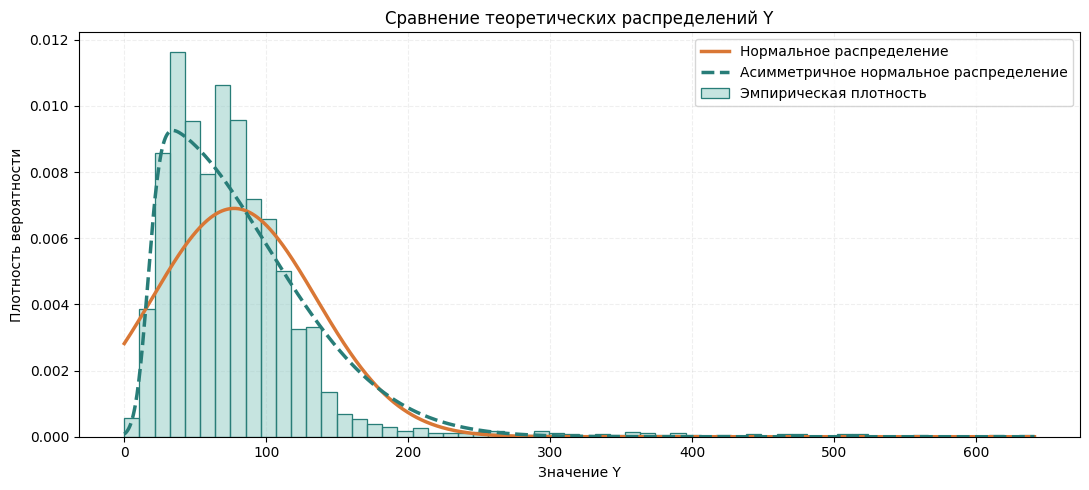

In [ ]:



y_values = Y.dropna().to_numpy()

normal_params_Y = stats.norm.fit(y_values)
skew_params_Y = stats.skewnorm.fit(y_values)


y_grid = np.linspace(y_values.min(), y_values.max(), 1000)

normal_pdf_Y = stats.norm.pdf(y_grid, *normal_params_Y)
skew_pdf_Y = stats.skewnorm.pdf(y_grid, *skew_params_Y)

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    y_values,
    bins=60,
    stat="density",
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.5,
    label="Эмпирическая плотность",
    ax=ax
)

ax.plot(
    y_grid,
    normal_pdf_Y,
    color="#D97735",
    linewidth=2.5,
    label="Нормальное распределение"
)

ax.plot(
    y_grid,
    skew_pdf_Y,
    color="#287D78",
    linewidth=2.5,
    linestyle="--",
    label="Асимметричное нормальное распределение"
)

ax.set_title("Сравнение теоретических распределений Y")
ax.set_xlabel("Значение Y")
ax.set_ylabel("Плотность вероятности")

ax.legend()
ax.grid(alpha=0.2, linestyle="--")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Сразу же заметно, что асимметричное нормальное распределение намного лучше описывает экспериментальные данные, чем симметричное нормальное распределение.

Однако обе модели недостаточно хорошо описывают экстремальные наблюдения и особенности правого хвоста.

Ну и таким образом можем сказать, что асимметричное распределение намного лучше описывает характер экмпериментальных данных, но не обеспечивает полного понимания картины.


Также, как и для X проведем стандартизацию случайной величины Y



Среднее: -0.0
Стандартное отклонение: 1.0


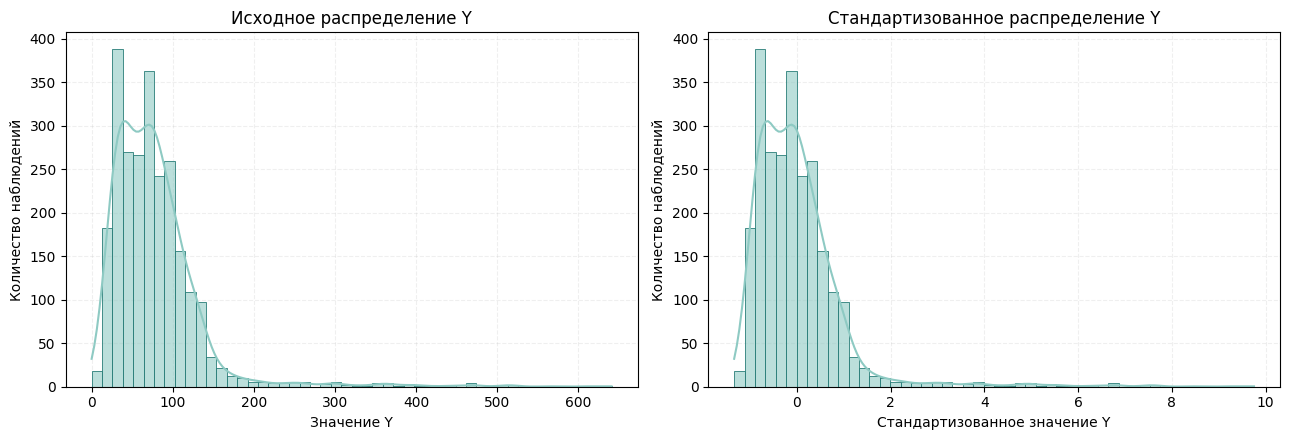

In [ ]:

# Стандартизация Y
Y_standardized = (Y - Y.mean()) / Y.std(ddof=1)

# Проверка
print("Среднее:", round(Y_standardized.mean(), 6))
print(
    "Стандартное отклонение:",
    round(Y_standardized.std(ddof=1), 6)
)

# Сравнение распределений
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(
    Y,
    bins=50,
    kde=True,
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.6,
    ax=axes[0]
)

axes[0].set_title("Исходное распределение Y")
axes[0].set_xlabel("Значение Y")
axes[0].set_ylabel("Количество наблюдений")

sns.histplot(
    Y_standardized,
    bins=50,
    kde=True,
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.6,
    ax=axes[1]
)

axes[1].set_title("Стандартизованное распределение Y")
axes[1].set_xlabel("Стандартизованное значение Y")
axes[1].set_ylabel("Количество наблюдений")

for ax in axes:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Опять же, форма графика и его характерные пики не поменялись, поменялся только мастштаб.

Таким образом, стандартизация позволяет сравнивать характеристики сенсорных откликов, измеряемые в разных масштабах, но не делает распределение нормальным.

### Independence & Estimations

Переходим к пункту с зависимостям и независимостям. Корреляцию и зависимость 3х случацных величин мы уже делали в предыдущем разделе, так что повторяться не будем.

Поэтому сразу же исследуем устойчивость оценок мат ожидания и дисперсии Y

Для этого мы возьмем весь исходный материал для аммиака(3009 строк) и будем многократно формировать выборки разного размера, сравнивая характеритики дисперсии и мат ожидания с характеристиками полной совокупности.


,n,Метод,Среднее оценок,SD среднего,Средняя дисперсия,SD дисперсии
0,20,Без возвращения,77.90,13.06,3393.31,3630.59
1,20,С возвращением,76.05,11.66,2993.96,3294.16
2,50,Без возвращения,77.62,7.85,3156.33,2027.41
3,50,С возвращением,77.82,8.31,3385.52,2231.94
4,100,Без возвращения,77.35,5.85,3224.00,1490.17
5,100,С возвращением,77.63,6.15,3309.94,1589.02
6,200,Без возвращения,77.93,3.96,3319.26,1076.15
7,200,С возвращением,77.91,4.20,3315.82,1166.52
8,500,Без возвращения,77.71,2.50,3283.14,676.87
9,500,С возвращением,77.84,2.70,3383.59,749.85


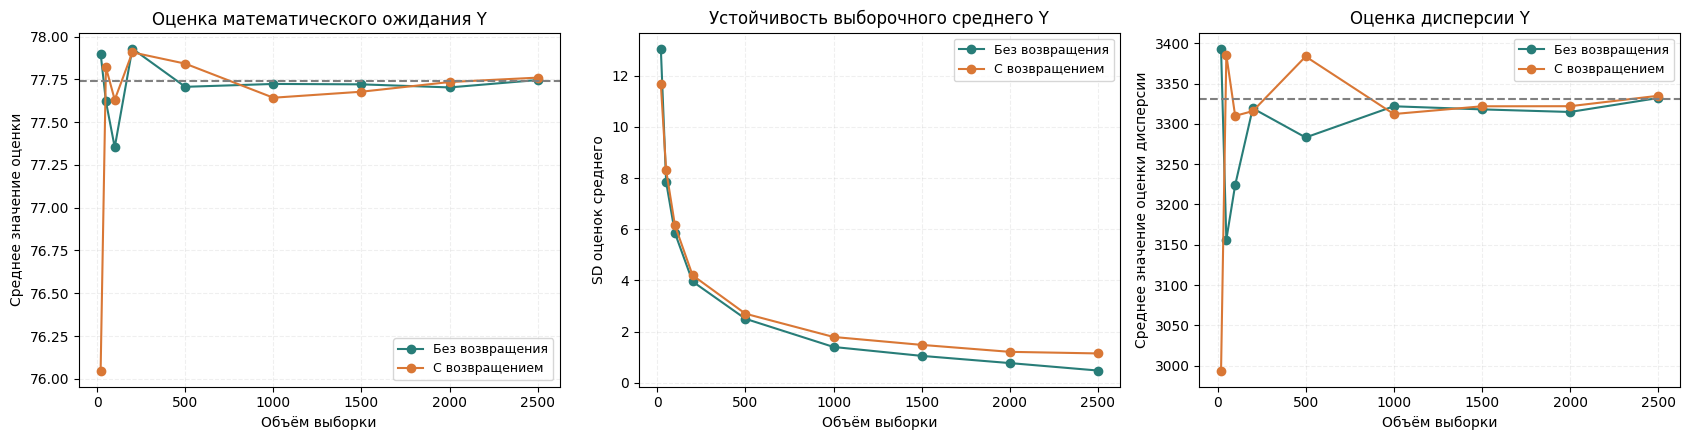

Выборочное среднее: 77.39
Стандартная ошибка: 0.48
95% доверительный интервал: [76.46; 78.32]


In [ ]:


population_Y = pd.to_numeric(
    general.loc[general["gas_id"] == 5, "feature_13"],
    errors="coerce"
).dropna().to_numpy()

y = Y.dropna().to_numpy()

mu_pop_Y = population_Y.mean()
var_pop_Y = population_Y.var(ddof=1)

# Параметры моделирования
sizes = [20, 50, 100, 200, 500, 1000, 1500, 2000, 2500]
repeats = 300
rng = np.random.default_rng(42)

results_Y = []

for n in sizes:
    for replace in [False, True]:

        means = []
        variances = []

        for _ in range(repeats):
            selected = rng.choice(
                population_Y,
                size=n,
                replace=replace
            )

            means.append(selected.mean())
            variances.append(selected.var(ddof=1))

        results_Y.append({
            "n": n,
            "Метод": "С возвращением" if replace else "Без возвращения",
            "Среднее оценок": np.mean(means),
            "SD среднего": np.std(means, ddof=1),
            "Средняя дисперсия": np.mean(variances),
            "SD дисперсии": np.std(variances, ddof=1)
        })

results_Y_df = pd.DataFrame(results_Y)

display(results_Y_df.round(2))


fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

palette = {
    "Без возвращения": "#287D78",
    "С возвращением": "#D97735"
}

# Оценка математического ожидания
for method, group in results_Y_df.groupby("Метод"):
    axes[0].plot(
        group["n"], group["Среднее оценок"],
        marker="o", color=palette[method], label=method
    )

axes[0].axhline(mu_pop_Y, color="gray", linestyle="--")
axes[0].set_title("Оценка математического ожидания Y")
axes[0].set_xlabel("Объём выборки")
axes[0].set_ylabel("Среднее значение оценки")

# Устойчивость выборочного среднего
for method, group in results_Y_df.groupby("Метод"):
    axes[1].plot(
        group["n"], group["SD среднего"],
        marker="o", color=palette[method], label=method
    )

axes[1].set_title("Устойчивость выборочного среднего Y")
axes[1].set_xlabel("Объём выборки")
axes[1].set_ylabel("SD оценок среднего")

# Оценка дисперсии
for method, group in results_Y_df.groupby("Метод"):
    axes[2].plot(
        group["n"], group["Средняя дисперсия"],
        marker="o", color=palette[method], label=method
    )

axes[2].axhline(var_pop_Y, color="gray", linestyle="--")
axes[2].set_title("Оценка дисперсии Y")
axes[2].set_xlabel("Объём выборки")
axes[2].set_ylabel("Среднее значение оценки дисперсии")

for ax in axes:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()



N = len(population_Y)
n = len(y)

mean_y = y.mean()
std_y = y.std(ddof=1)

# Стандартная ошибка с поправкой на конечную совокупность
se_y = (
    std_y / np.sqrt(n)
    * np.sqrt((N - n) / (N - 1))
)

critical = stats.t.ppf(0.975, df=n - 1)

ci_lower_y = mean_y - critical * se_y
ci_upper_y = mean_y + critical * se_y

print(f"Выборочное среднее: {mean_y:,.2f}")
print(f"Стандартная ошибка: {se_y:,.2f}")
print(
    f"95% доверительный интервал: "
    f"[{ci_lower_y:,.2f}; {ci_upper_y:,.2f}]"
)



Результаты показали, что при увеличении количества наблюдений оценки становятся стабильнее и приближаются к характеристикам полной совокупности. Особенно заметно уменьшается разброс выборочного среднего: при отборе без возвращения его стандартное отклонение снизилось с 13,06 до 0,48.

Для больших выборок метод без возвращения обеспечивает меньшую изменчивость оценок по сравнению с отбором с возвращением. Аналогичная тенденция наблюдается при исследовании дисперсии.



## Random Variable 03 — Z

### Describtion

в качестве 3ей случайной величины была выбрана характеристика спада отклика уже на 3м сенсоре, расчитанного тем же способом, что и величина Y, поэтому возможно, рещультаты анализа будут в чем-то схожи с предыдущей величиной.



---

**Стахометрическая природа**

В рамках исследования случайный эксперимент — это равновероятный выбор одного наблюдения из экспериментальной выборки.

Значение Z заранее неизвестно, поскольку измерения проводились при разных концентрациях аммиака, в различных экспериментальных партиях и условиях.

Следовательно, Z является случайной величиной относительно данного эксперимента. При этом её значения могут зависеть от физико-химических характеристик сенсора и условий измерения.

### EDA & Distribution

Расчитываем все характеристики

In [ ]:


Z = sample["feature_24"].dropna().copy()

stats_Z = pd.Series({
    "Количество наблюдений": Z.count(),
    "Среднее": Z.mean(),
    "Медиана": Z.median(),
    "Дисперсия": Z.var(ddof=1),
    "Стандартное отклонение": Z.std(ddof=1),
    "Минимум": Z.min(),
    "Q1 (25%)": Z.quantile(0.25),
    "Q3 (75%)": Z.quantile(0.75),
    "IQR": Z.quantile(0.75) - Z.quantile(0.25),
    "Максимум": Z.max(),
    "Асимметрия": Z.skew(),
    "Эксцесс": Z.kurt()
})

display(
    stats_Z.to_frame(name="Значение").style.format(
        "{:,.2f}",
        thousands=" ",
        decimal=","
    )
)


,Значение
Количество наблюдений,"2 500,00"
Среднее,"-17,30"
Медиана,"-13,31"
Дисперсия,"233,49"
Стандартное отклонение,"15,28"
Минимум,"-144,60"
Q1 (25%),"-21,35"
Q3 (75%),"-8,96"
IQR,"12,39"
Максимум,"-0,44"


Вопреки ожиданиям, эта величина отличается от двух предыдущих довольно сильно, прежде всего тем, что значения у этой величины отрицательное, что может объясняться тем, что величина описыват спад отклика.

Ассиметрия также другая, она левосторонняя, высокий положительный эксцесс  указывает на выраженные крайние отклонения относительно нормального распределения.

Также посмотрим на это все в формате графиков

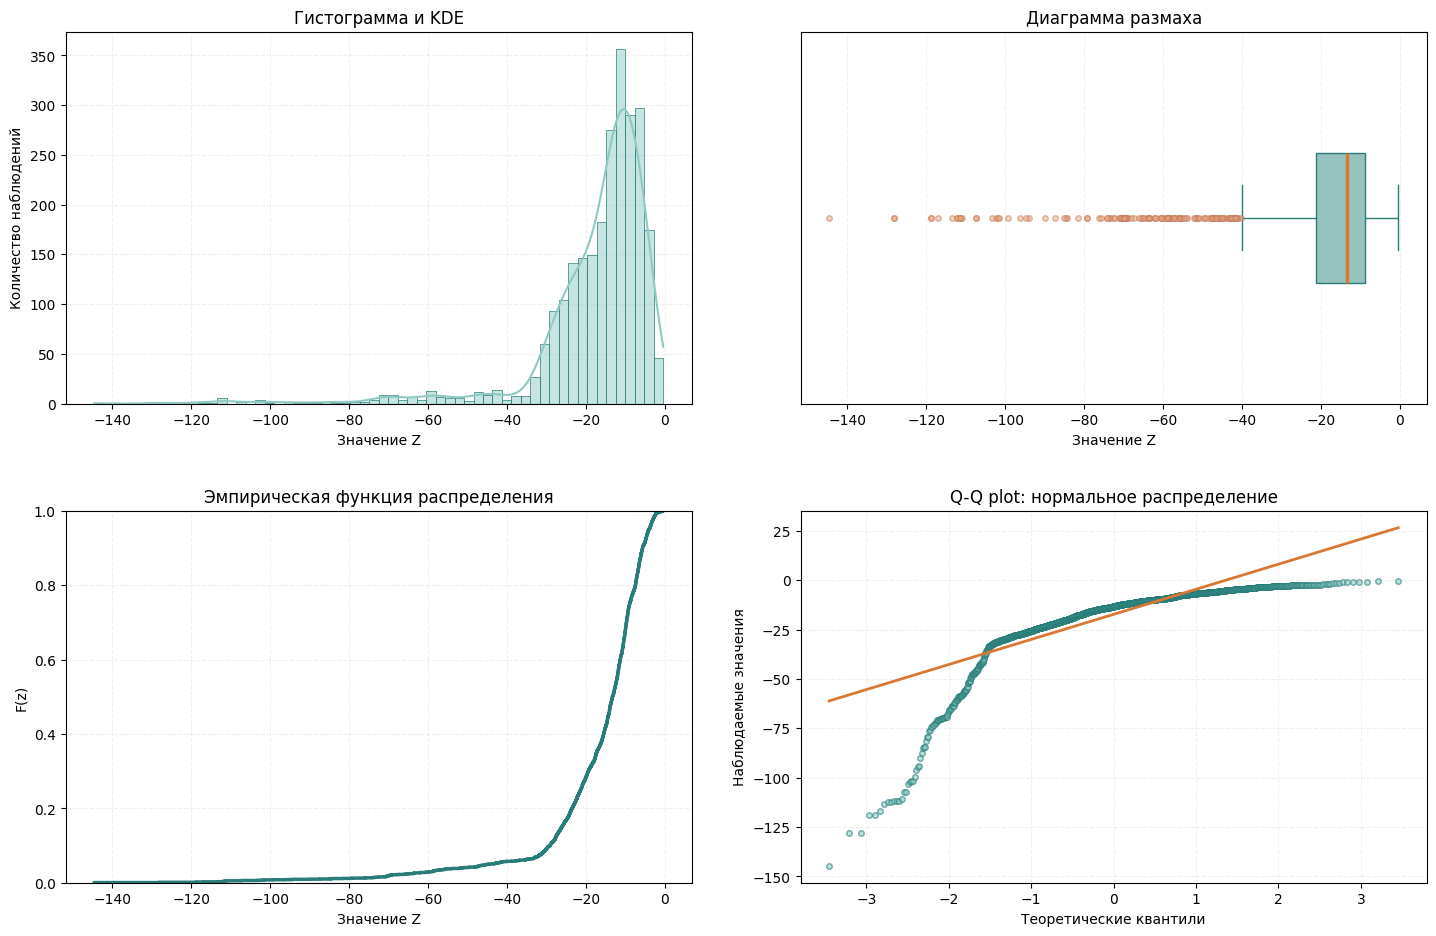

In [ ]:


fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(
    Z, bins=60, kde=True,
    color="#8ECAC3",
    edgecolor="#287D78",
    linewidth=0.5,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Гистограмма и KDE")
axes[0, 0].set_xlabel("Значение Z")
axes[0, 0].set_ylabel("Количество наблюдений")


sns.boxplot(
    x=Z,
    color="#8ECAC3",
    width=0.35,
    boxprops={"edgecolor": "#287D78"},
    medianprops={"color": "#D97735", "linewidth": 2.5},
    whiskerprops={"color": "#287D78"},
    capprops={"color": "#287D78"},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#E5A37E",
        "markeredgecolor": "#C47C59",
        "markersize": 4,
        "alpha": 0.5
    },
    ax=axes[0, 1]
)
axes[0, 1].set_title("Диаграмма размаха")
axes[0, 1].set_xlabel("Значение Z")
axes[0, 1].set_yticks([])

# 3. ECDF
sns.ecdfplot(
    x=Z,
    color="#287D78",
    linewidth=2.5,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Эмпирическая функция распределения")
axes[1, 0].set_xlabel("Значение Z")
axes[1, 0].set_ylabel("F(z)")

# 4. Q-Q plot
stats.probplot(Z, dist="norm", plot=axes[1, 1])

qq_ax = axes[1, 1]
qq_ax.get_lines()[0].set_markerfacecolor("#8ECAC3")
qq_ax.get_lines()[0].set_markeredgecolor("#287D78")
qq_ax.get_lines()[0].set_markersize(4)
qq_ax.get_lines()[0].set_alpha(0.6)
qq_ax.get_lines()[1].set_color("#D97735")
qq_ax.get_lines()[1].set_linewidth(2)

qq_ax.set_title("Q-Q plot: нормальное распределение")
qq_ax.set_xlabel("Теоретические квантили")
qq_ax.set_ylabel("Наблюдаемые значения")

for ax in axes.flat:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)

plt.tight_layout(pad=3)
plt.show()


Тут опять же бросается в глаза левостороння симметрия.

1) Гистограмма и KDE
Гистограмма показывает, что большинство значений сосредоточено примерно в диапазоне от -35 до 0

кривая KDE показывает один широкий максимум(чего нет в X, Y)

2) Диаграма размаха
Диаграмма размаха подтверждает наличие потенциальных выбросов в области значительных отрицательных откликов

3) Эмпирическая функция распределения
Эмпирическая функция распределения показывает быстрое накопление наблюдений в области значений, близких к нулю.

4) Q-Q plot
На Q–Q plot наблюдаются существенные отклонения от теоретической прямой, особенно в левом хвосте, что свидетельствует о несоответствии экспериментального распределения нормальной модели.

**Сравним теоретические распределения(симметричное и асимметричное) **



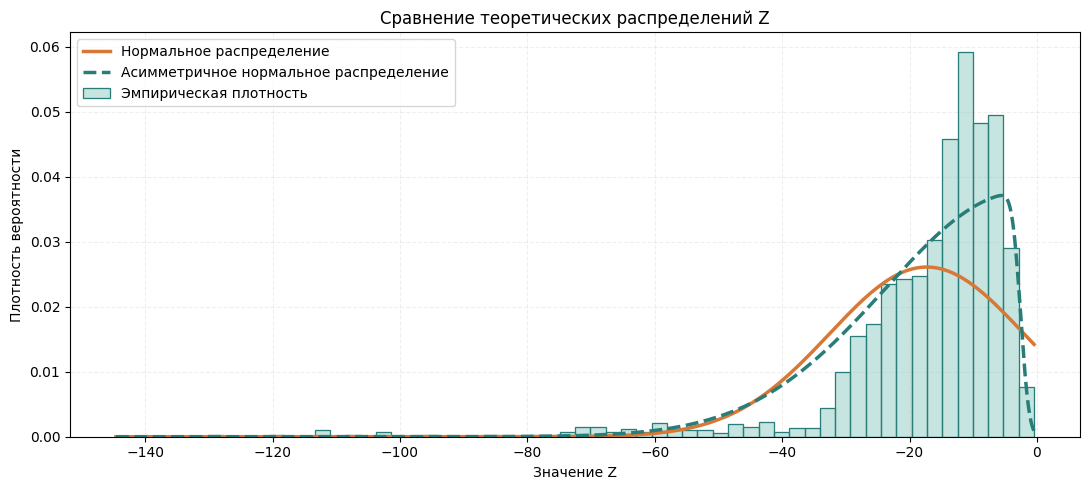

In [ ]:


z_values = Z.dropna().to_numpy()

normal_params_Z = stats.norm.fit(z_values)
skew_params_Z = stats.skewnorm.fit(z_values)

z_grid = np.linspace(z_values.min(), z_values.max(), 1000)

normal_pdf_Z = stats.norm.pdf(z_grid, *normal_params_Z)
skew_pdf_Z = stats.skewnorm.pdf(z_grid, *skew_params_Z)

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    z_values,
    bins=60,
    stat="density",
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.5,
    label="Эмпирическая плотность",
    ax=ax
)

ax.plot(
    z_grid,
    normal_pdf_Z,
    color="#D97735",
    linewidth=2.5,
    label="Нормальное распределение"
)

ax.plot(
    z_grid,
    skew_pdf_Z,
    color="#287D78",
    linewidth=2.5,
    linestyle="--",
    label="Асимметричное нормальное распределение"
)

ax.set_title("Сравнение теоретических распределений Z")
ax.set_xlabel("Значение Z")
ax.set_ylabel("Плотность вероятности")

ax.legend()
ax.grid(alpha=0.2, linestyle="--")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


И опять асимметричное распределение намного лучше описывает то, что происходит в эмпирических значениях.


Однако обе модели недостаточно хорошо воспроизводят отдельные экстремальные значения и особенности длинного левого хвоста.


Таким образом, асимметричное нормальное распределение лучше отражает общую форму распределения Z, но не обеспечивает полного соответствия экспериментальным данным.

Перейдем к стандартизации.

Среднее: 0.0
Стандартное отклонение: 1.0


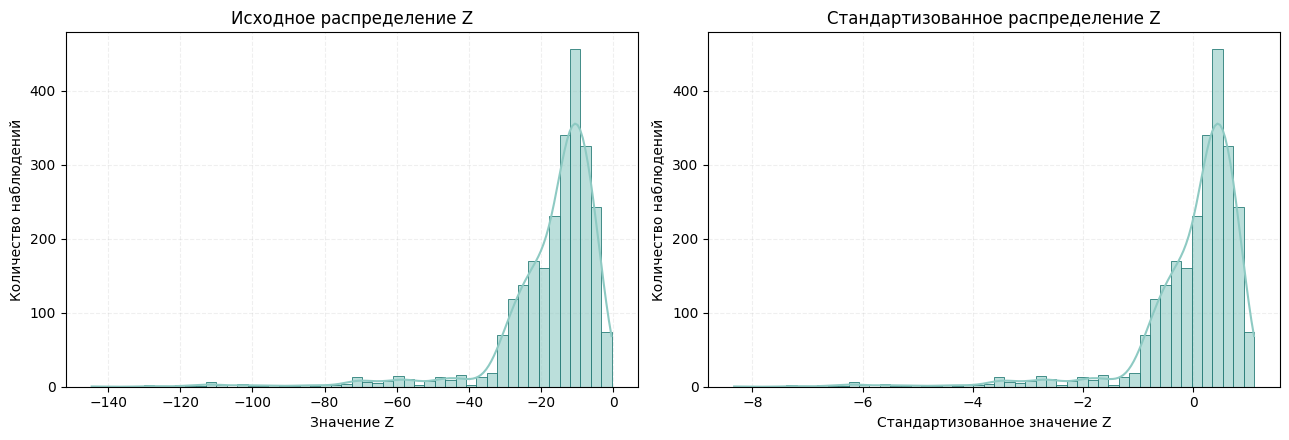

In [ ]:

# Стандартизация третьей случайной величины
Z_standardized = (Z - Z.mean()) / Z.std(ddof=1)

# Проверяем результат
print("Среднее:", round(Z_standardized.mean(), 6))
print(
    "Стандартное отклонение:",
    round(Z_standardized.std(ddof=1), 6)
)

# Сравниваем распределения
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(
    Z,
    bins=50,
    kde=True,
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.6,
    ax=axes[0]
)

axes[0].set_title("Исходное распределение Z")
axes[0].set_xlabel("Значение Z")
axes[0].set_ylabel("Количество наблюдений")

sns.histplot(
    Z_standardized,
    bins=50,
    kde=True,
    color="#8ECAC3",
    edgecolor="#287D78",
    alpha=0.6,
    ax=axes[1]
)

axes[1].set_title("Стандартизованное распределение Z")
axes[1].set_xlabel("Стандартизованное значение Z")
axes[1].set_ylabel("Количество наблюдений")

for ax in axes:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Для приведения значений случайной величины Z к единому масштабу была выполнена стандартизация методом Z-score.

После преобразования выборочное среднее стало равным нулю, а стандартное отклонение — единице. При этом форма распределения сохранилась, включая выраженную левостороннюю асимметрию и наличие крайних отрицательных значений.

### Independence & Estimations

Для исследования устойчивости оценок математического ожидания и дисперсии случайной величины Z рассмотрим выборки различного объёма.

Для каждого объёма проведём по 300 случайных отборов с возвращением и без возвращения. Полученные оценки сравним с характеристиками всех доступных измерений аммиака.

Это позволит оценить, насколько увеличение числа наблюдений и выбранный способ отбора влияют на точность и устойчивость статистических оценок.

,n,Метод,Среднее оценок,SD среднего,Средняя дисперсия,SD дисперсии
0,20,Без возвращения,-17.29,3.11,235.41,211.17
1,20,С возвращением,-17.04,3.21,219.05,215.59
2,50,Без возвращения,-17.28,2.28,226.24,135.64
3,50,С возвращением,-17.46,2.13,237.63,136.00
4,100,Без возвращения,-17.32,1.50,226.73,86.32
5,100,С возвращением,-17.35,1.66,237.02,101.87
6,200,Без возвращения,-17.35,1.10,232.79,67.57
7,200,С возвращением,-17.41,1.12,233.97,70.00
8,500,Без возвращения,-17.38,0.64,234.24,42.03
9,500,С возвращением,-17.39,0.71,235.49,45.16


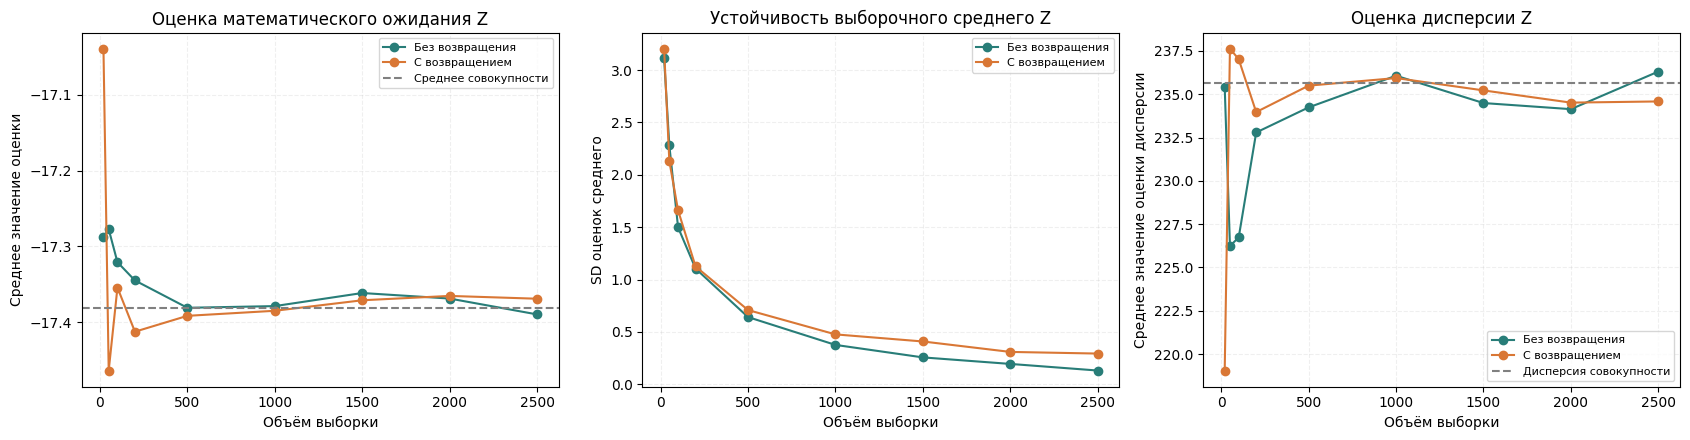

In [ ]:


population_Z = pd.to_numeric(
    general.loc[general["gas_id"] == 5, "feature_24"],
    errors="coerce"
).dropna().to_numpy()
z = Z.dropna().to_numpy()

mu_pop_Z = population_Z.mean()
var_pop_Z = population_Z.var(ddof=1)

# Параметры эксперимента
sizes = [20, 50, 100, 200, 500, 1000, 1500, 2000, 2500]
repeats = 300
rng = np.random.default_rng(42)

results_Z = []

for n in sizes:
    for replace in [False, True]:

        means = []
        variances = []

        for _ in range(repeats):
            selected = rng.choice(
                population_Z,
                size=n,
                replace=replace
            )

            means.append(selected.mean())
            variances.append(selected.var(ddof=1))

        results_Z.append({
            "n": n,
            "Метод": "С возвращением" if replace else "Без возвращения",
            "Среднее оценок": np.mean(means),
            "SD среднего": np.std(means, ddof=1),
            "Средняя дисперсия": np.mean(variances),
            "SD дисперсии": np.std(variances, ddof=1)
        })

results_Z_df = pd.DataFrame(results_Z)

display(results_Z_df.round(2))


fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

palette = {
    "Без возвращения": "#287D78",
    "С возвращением": "#D97735"
}

for method, group in results_Z_df.groupby("Метод"):
    axes[0].plot(
        group["n"],
        group["Среднее оценок"],
        marker="o",
        color=palette[method],
        label=method
    )

axes[0].axhline(
    mu_pop_Z, color="gray", linestyle="--",
    label="Среднее совокупности"
)
axes[0].set_title("Оценка математического ожидания Z")
axes[0].set_xlabel("Объём выборки")
axes[0].set_ylabel("Среднее значение оценки")

for method, group in results_Z_df.groupby("Метод"):
    axes[1].plot(
        group["n"],
        group["SD среднего"],
        marker="o",
        color=palette[method],
        label=method
    )

axes[1].set_title("Устойчивость выборочного среднего Z")
axes[1].set_xlabel("Объём выборки")
axes[1].set_ylabel("SD оценок среднего")

for method, group in results_Z_df.groupby("Метод"):
    axes[2].plot(
        group["n"],
        group["Средняя дисперсия"],
        marker="o",
        color=palette[method],
        label=method
    )

axes[2].axhline(
    var_pop_Z, color="gray", linestyle="--",
    label="Дисперсия совокупности"
)
axes[2].set_title("Оценка дисперсии Z")
axes[2].set_xlabel("Объём выборки")
axes[2].set_ylabel("Среднее значение оценки дисперсии")

for ax in axes:
    ax.grid(alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()



Полученные результаты показали, что при увеличении объёма выборки средние оценки приближаются к характеристикам полной совокупности, а их разброс значительно уменьшается.

При отборе без возвращения стандартное отклонение оценок среднего снизилось с 3,11 до 0,13, а стандартное отклонение оценок дисперсии — с 211,17 до 8,08 при увеличении числа наблюдений с 20 до 2500.

Для больших объёмов выборки метод без возвращения обеспечивает меньшую изменчивость оценок по сравнению с отбором с возвращением.

## Lab resume

 Проверка статистической гипотезы

В ходе корреляционного анализа между случайными величинами Y и Z была обнаружена отрицательная линейная связь (r = −0,713).

Проверим, является ли эта корреляция статистически значимой с помощью корреляционного теста Пирсона.

Сформулируем гипотезы:

- **H₀: ρ = 0** — линейная корреляция отсутствует.
- **H₁: ρ ≠ 0** — существует ненулевая линейная корреляция.

Уровень значимости примем равным α = 0,05.

> Добавить блок с цитатой



In [ ]:



hyp_data = sample[
    ["feature_13", "feature_24"]
].dropna()

Y_test = hyp_data["feature_13"]
Z_test = hyp_data["feature_24"]

r, p_value = stats.pearsonr(Y_test, Z_test)

alpha = 0.05

print(f"Количество наблюдений: {len(hyp_data)}")
print(f"Коэффициент корреляции: {r:.4f}")
print(f"p-value: {p_value:.3e}")
print(f"Уровень значимости: {alpha}")

if p_value < alpha:
    print("H0 отвергается: корреляция статистически значима.")
else:
    print("Нет оснований отвергнуть H0.")


Количество наблюдений: 2500
Коэффициент корреляции: -0.7125
p-value: 0.000e+00
Уровень значимости: 0.05
H0 отвергается: корреляция статистически значима.


В результате проверки гипотезы по 2500 наблюдениям получен коэффициент корреляции Пирсона r = −0,7125.

Полученное p-value значительно меньше уровня значимости 0,05, поэтому нулевая гипотеза отвергается.

В итоге, подтверждается гипотеза о том, что связь между X и Z статистически значима. В целом, это логично, так как все они характеризуют примерно одно и то же, так что статистически значимые зависимости точно должны быть.

Но важно отметить, что эта корреляция не доказывает причинно-следственную связь.



---
Общие результаты и выводы

В ходе работы мы исследовали большой датасет [Gas Sensor Array Drift at Different Concentrations](https://archive.ics.uci.edu/dataset/270/gas%2Bsensor%2Barray%2Bdrift%2Bdataset%2Bat%2Bdifferent%2Bconcentrations?$0)., соделржащего довольно интересные и немного странные, как выяснилось позже исследования.


Для хоть какого-то понятного анализа были выбраны 3009 строчек исследования, которые показывают результаты эксперимента только для аммиака. Из них случайно была сформирована выборка из 2500 значений.

В самом начале исследования датасета мы столкнулись с проблемой, заявленные характеристики датасета неправильные, они путают, поэтому был проведен дополнительный анализ, мы сопоставляли реальные и заявленные характеристики. В итоге пришли к какой-то истине.

Были рассмотрены три случайные величины, характеризующие разные особенности работы газовых сенсоров:


*   X — максимальное изменение сопротивления первого сенсора;
*   Y — характеристика нарастания отклика второго сенсора;
*   Z — характеристика спада отклика третьего сенсора.

Для каждой величины были рассчитаны описательные статистики и построены графики, проведена стандартизация и рассмотрены теоретические модели распрделения.

Анализ показал, что для всех трёх величин распределени отличается от нормального. Величины X и Y имеют положительную симметрию, а Z - отрицательную. Во многом из-за этого для описания экспериментальных данных была использована асимметричная модель нормализации, но, к сожалению, даже эта модель не полностью описывает все данные.

Дополнительно было исследовано влияние концентрации аммиака и экспериментальной партии на величину X. Обнаружены заметные различия откликов между партиями, которые сохраняются даже при фиксированной концентрации. Это согласуется с возможным влиянием дрейфа сенсоров.

Корреляционный анализ выявил статистические связи между выбранными характеристиками:

X и Y: r = 0,566;

X и Z: r = −0,219;

Y и Z: r = −0,713.

Наиболее выраженная линейная связь наблюдается между Y и Z. Проверка гипотезы с помощью теста Пирсона показала, что отрицательная корреляция между ними статистически значима при уровне значимости 0,05 в рамках предположений теста.









---



Мы считаем, что статистический анализ получился довольно содержательным и полезным, несмотря на проблемность датасета во всех его проявлениях.

Это был довольно полезный опыт в статистике, который поможет нам в будущем анализировать химические(и не только) датасеты уже в научной деятельности с полным пониманием дела.


### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
|        |               |       |         |


### Литература



1. Vergara A. *Gas Sensor Array Drift at Different Concentrations* [Электронный ресурс] // UCI Machine Learning Repository. — 2012. — DOI: [10.24432/C5MK6M](https://doi.org/10.24432/C5MK6M).

2. Vergara A., Vembu S., Ayhan T., Ryan M. A., Homer M. L., Huerta R. Chemical gas sensor drift compensation using classifier ensembles // Sensors and Actuators B: Chemical. — 2012. — Vol. 166–167. — P. 320–329. — DOI: [10.1016/j.snb.2012.01.074](https://doi.org/10.1016/j.snb.2012.01.074).

3. Rodríguez-Luján I., Fonollosa J., Vergara A., Homer M., Huerta R. On the calibration of sensor arrays for pattern recognition using the minimal number of experiments // Chemometrics and Intelligent Laboratory Systems. — 2014. — Vol. 130. — P. 123–134. — DOI: [10.1016/j.chemolab.2013.10.012](https://doi.org/10.1016/j.chemolab.2013.10.012).

4. Fonollosa J., Rodríguez-Luján I., Huerta R. Chemical gas sensor array dataset // Data in Brief. — 2015. — Vol. 3. — P. 85–89. — DOI: [10.1016/j.dib.2015.01.003](https://doi.org/10.1016/j.dib.2015.01.003).

5. Heckert N. A., Filliben J. J. NIST/SEMATECH e-Handbook of Statistical Methods. Chapter 1: Exploratory Data Analysis [Электронный ресурс]. — National Institute of Standards and Technology, 2003. — URL: https://www.nist.gov/publications/nistsematech-e-handbook-statistical-methods-chapter-1-exploratory-data-analysis.

6. SciPy Developers. *SciPy Statistical Functions* [Электронный ресурс]. — Официальная документация библиотеки SciPy. — URL: https://docs.scipy.org/doc/scipy/reference/stats.html.

7. pandas Development Team. *pandas.DataFrame.corr* [Электронный ресурс]. — Официальная документация pandas. — URL: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html.